# Predicting the final size of US wildfires at discovery time

Hands-on Machine Learning, S1 DKAI

Group: Hugo Ramillon, Sasha Sutton

Data: "1.88 Million US Wildfires" on Kaggle (https://www.kaggle.com/datasets/rtatman/188-million-us-wildfires). It is the FPA FOD database: Short, K. C. (2017), Spatial wildfire occurrence data for the United States, 1992-2015 [FPA_FOD_20170508], 4th edition, USDA Forest Service Research Data Archive, https://doi.org/10.2737/RDS-2013-0009.4.

The data is not included with this notebook. To run it, unzip the Kaggle archive and put the SQLite file at `../data/data.sqlite`.

Plan:
1. Introduction
2. Preprocessing: loading, choice of columns and leakage check, cleaning, split, exploration, encoding
3. Training: model comparison, tuning, learning curve, PCA, ablation study
4. Evaluation on the test set
5. Conclusion

## 1. Introduction

### 1.1 Task
The dataset contains every wildfire reported in the US between 1992 and 2015, about 1.88 million fires. For each fire we know where and when it was discovered, who reported it, its cause, who owns the land, and at the end how much area it burned (`FIRE_SIZE`, in acres).

We want to predict the final burned area of a fire using only what is known when the fire is discovered. An estimate at that moment could help decide which fires need resources first. The target is only known once the fire is out, while the inputs are recorded when the fire is reported. It also matches the project guidelines: tabular data, many rows, more than 10 features and a target that is not trivial to predict.

### 1.2 How we set up the problem
- Target: `log(1 + FIRE_SIZE)`. Sizes go from 0.00001 to about 600,000 acres. Most fires are tiny and a few are huge, so with the raw size a squared error would be driven by a handful of very large fires. With the log, an error of 0.7 means a prediction off by a factor of about 2, whatever the size of the fire. Getting the order of magnitude right is what matters in practice. The `1 +` avoids `log(0)`.
- We do regression and not classification of the size classes A to G. The classes are just intervals of the size, so predicting a number keeps their order (confusing A with G is worse than confusing A with B), and we can still convert a prediction back into a class.
- Two scenarios. Scenario A (our main one) only uses information available at discovery. Scenario B adds the duration of the fire (containment date minus discovery date). The duration is only known once the fire is under control, so it cannot be used for an early prediction. We keep it to measure how much it would inflate the results.
- Metrics, all on the log scale: R² (share of the variance explained, 0 means no better than always predicting the mean), RMSE and MAE. We also convert predictions to size classes and report the accuracy, but this metric is weak here because always predicting class B is already right for about 45 % of fires.

### 1.3 State of the art
| Work | Task | Method | Result |
|---|---|---|---|
| Kaggle notebooks, [JamesonThai/wildfire](https://github.com/JamesonThai/wildfire) | cause of the fire | random forest, XGBoost | about 60 % accuracy for 13 causes, 80 % for 3 groups |
| UCLA thesis ([eScholarship](https://escholarship.org/uc/item/44j0g4pk)) | fire size | XGBoost, CatBoost, random forest, GLM, MLP | boosting is best, the imbalance between small and large fires is the main difficulty |
| [NHSJS paper](https://nhsjs.com/?p=23708) | size class (5 classes) | logistic regression, MLP | above 82 % accuracy, mostly because small fires dominate |
| Koh (2023), Extremes ([paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC10115709/)) | burned area per grid cell and month (EVA 2021 challenge) | gradient boosting with losses for extreme values | 2nd of 28 teams; splitting by space and time estimates the test error better than random K-fold |
| Pourmohamad et al. (2024), ESSD ([paper](https://essd.copernicus.org/articles/16/3045/2024/essd-16-3045-2024.html)) | FPA FOD with about 270 extra variables (weather, vegetation, population) | dataset paper | richer environmental data is the natural next step |

What we take from this: gradient boosted trees are the reference model on this kind of data, accuracies on size classes look high only because most fires are small, and the way the data is split changes the results a lot.

What we do differently: we predict the continuous size at discovery time, we check every column for leakage, we split by year (train on the past, test on the future), we compare several model families, tune the best one, try PCA and run an ablation study on groups of features.

In [1]:
import sqlite3
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, mean_absolute_error,
                             precision_recall_curve, r2_score, roc_auc_score, root_mean_squared_error)
from sklearn.model_selection import KFold, PredefinedSplit, RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 80})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
DATA_PATH = Path("../data/data.sqlite")

## 2. Preprocessing

### 2.1 Loading the data
The file is a SQLite database of about 800 MB and the fires are in the `Fires` table. Before loading anything we compute, directly in SQL, the share of missing values and the number of distinct values of every column. It is fast, uses little memory, and it gives us the facts we need to choose the columns.

In [2]:
with sqlite3.connect(DATA_PATH) as db:
    all_columns = [c for c in pd.read_sql_query("SELECT * FROM Fires LIMIT 1", db).columns if c != "Shape"]
    stats_sql = ", ".join(f'SUM({c} IS NULL OR TRIM({c}) = \'\') AS "{c}__missing", COUNT(DISTINCT {c}) AS "{c}__unique"'
                          for c in all_columns)
    stats = pd.read_sql_query(f"SELECT COUNT(*) AS n_rows, {stats_sql} FROM Fires", db).iloc[0]
    first_row = pd.read_sql_query("SELECT * FROM Fires LIMIT 1", db).drop(columns="Shape").iloc[0]

n_rows = int(stats["n_rows"])
column_overview = pd.DataFrame({
    "missing_%": [100 * stats[f"{c}__missing"] / n_rows for c in all_columns],
    "n_unique": [int(stats[f"{c}__unique"]) for c in all_columns],
    "example": [first_row[c] for c in all_columns],
}, index=all_columns)
print(f"{n_rows:,} fires, {len(all_columns)} columns (plus the 'Shape' geometry column that we ignore)")

1,880,465 fires, 38 columns (plus the 'Shape' geometry column that we ignore)


### 2.2 Which columns can we use?
We went through all 38 columns and gave each one a role:
- feature: known when the fire is discovered, used in scenario A
- post-event: only known after the fire (containment date and time). Only used to compute the duration for scenario B.
- leakage: only filled because the fire became large, or directly computed from the size. Never used as a feature.
- redundant: same information as a column we keep (for example a code and its description)
- identifier: ids and free text without predictive meaning, or too incomplete (the county is missing for 36 % of fires, and latitude/longitude give the location anyway)

In [3]:
COLUMN_ROLES = {
    "OBJECTID": ("identifier", "row id"),
    "FOD_ID": ("identifier", "global fire id"),
    "FPA_ID": ("identifier", "FPA id"),
    "SOURCE_SYSTEM_TYPE": ("feature", "FED / NONFED / INTERAGCY reporting system"),
    "SOURCE_SYSTEM": ("feature", "database the record comes from (IA-ICS209 records are removed, see below)"),
    "NWCG_REPORTING_AGENCY": ("feature", "agency that reported the fire"),
    "NWCG_REPORTING_UNIT_ID": ("feature", "unit that reported the fire (1,640 values)"),
    "NWCG_REPORTING_UNIT_NAME": ("redundant", "name of NWCG_REPORTING_UNIT_ID"),
    "SOURCE_REPORTING_UNIT": ("redundant", "source system version of the reporting unit"),
    "SOURCE_REPORTING_UNIT_NAME": ("redundant", "name of SOURCE_REPORTING_UNIT"),
    "LOCAL_FIRE_REPORT_ID": ("identifier", "local id"),
    "LOCAL_INCIDENT_ID": ("identifier", "local id"),
    "FIRE_CODE": ("identifier", "suppression cost code"),
    "FIRE_NAME": ("leakage", "free text, large fires get a name more often"),
    "ICS_209_INCIDENT_NUMBER": ("leakage", "only filed for large or complex incidents"),
    "ICS_209_NAME": ("leakage", "only filed for large or complex incidents"),
    "MTBS_ID": ("leakage", "MTBS only maps fires above 1000 ac (West) / 500 ac (East)"),
    "MTBS_FIRE_NAME": ("leakage", "same as MTBS_ID"),
    "COMPLEX_NAME": ("leakage", "fires grouped in a complex are large"),
    "FIRE_YEAR": ("feature", "year of discovery"),
    "DISCOVERY_DATE": ("feature", "Julian date, gives month and weekday"),
    "DISCOVERY_DOY": ("feature", "day of the year"),
    "DISCOVERY_TIME": ("feature", "HHMM, gives the hour of discovery"),
    "STAT_CAUSE_CODE": ("redundant", "code of STAT_CAUSE_DESCR"),
    "STAT_CAUSE_DESCR": ("feature", "cause (13 values)"),
    "CONT_DATE": ("post-event", "containment date, only for the duration (scenario B)"),
    "CONT_DOY": ("redundant", "day of year of CONT_DATE"),
    "CONT_TIME": ("post-event", "containment time, only for the duration (scenario B)"),
    "FIRE_SIZE": ("target", "final burned area (acres)"),
    "FIRE_SIZE_CLASS": ("leakage", "size class A-G computed from FIRE_SIZE, only used for evaluation"),
    "LATITUDE": ("feature", "location"),
    "LONGITUDE": ("feature", "location"),
    "OWNER_CODE": ("redundant", "code of OWNER_DESCR"),
    "OWNER_DESCR": ("feature", "land owner (16 values)"),
    "STATE": ("feature", "state (52 values)"),
    "COUNTY": ("identifier", "36 % missing, mix of codes and names"),
    "FIPS_CODE": ("identifier", "36 % missing"),
    "FIPS_NAME": ("identifier", "36 % missing"),
}
column_overview["role"] = [COLUMN_ROLES[c][0] for c in all_columns]
column_overview["reason"] = [COLUMN_ROLES[c][1] for c in all_columns]
print(column_overview["role"].value_counts().to_string())
column_overview

role
feature       13
identifier     9
leakage        7
redundant      6
post-event     2
target         1


,missing_%,n_unique,example,role,reason
OBJECTID,0.0000,1880465,1,identifier,row id
FOD_ID,0.0000,1880465,1,identifier,global fire id
FPA_ID,0.0000,1880462,FS-1418826,identifier,FPA id
SOURCE_SYSTEM_TYPE,0.0000,3,FED,feature,FED / NONFED / INTERAGCY reporting system
SOURCE_SYSTEM,0.0000,38,FS-FIRESTAT,feature,database the record comes from (IA-ICS209 reco...
NWCG_REPORTING_AGENCY,0.0000,11,FS,feature,agency that reported the fire
NWCG_REPORTING_UNIT_ID,0.0000,1640,USCAPNF,feature,"unit that reported the fire (1,640 values)"
NWCG_REPORTING_UNIT_NAME,0.0000,1635,Plumas National Forest,redundant,name of NWCG_REPORTING_UNIT_ID
SOURCE_REPORTING_UNIT,0.0000,4992,0511,redundant,source system version of the reporting unit
SOURCE_REPORTING_UNIT_NAME,0.0000,4441,Plumas National Forest,redundant,name of SOURCE_REPORTING_UNIT


Leakage is the biggest risk with this dataset: a column that is only filled because the fire became large would make the model look very good and be useless at discovery time. For each column we suspected, we compare the share of large fires (100 acres or more) when the column is filled and when it is empty. We do this on the training years only (1992-2011, see 2.4), so that no decision is based on the years we test on.

We also look at one value of `SOURCE_SYSTEM`. `IA-ICS209` means the record was created from an ICS-209 incident report, and these reports are only written for large or complex incidents.

In [4]:
LOAD_COLUMNS = [
    "FIRE_YEAR", "DISCOVERY_DATE", "DISCOVERY_DOY", "DISCOVERY_TIME", "CONT_DATE", "CONT_TIME",
    "STAT_CAUSE_DESCR", "FIRE_SIZE", "FIRE_SIZE_CLASS", "LATITUDE", "LONGITUDE", "STATE", "COUNTY",
    "OWNER_DESCR", "NWCG_REPORTING_AGENCY", "NWCG_REPORTING_UNIT_ID", "SOURCE_SYSTEM_TYPE", "SOURCE_SYSTEM",
    "FIRE_NAME", "MTBS_ID", "ICS_209_INCIDENT_NUMBER", "COMPLEX_NAME",
]
with sqlite3.connect(DATA_PATH) as db:
    raw = pd.read_sql_query(f"SELECT {', '.join(LOAD_COLUMNS)} FROM Fires", db)

raw_train_years = raw[raw["FIRE_YEAR"] <= 2011]
is_large = raw_train_years["FIRE_SIZE"] >= 100
leak_check = {}
for col in ["MTBS_ID", "ICS_209_INCIDENT_NUMBER", "COMPLEX_NAME", "FIRE_NAME"]:
    values = raw_train_years[col]
    leak_check[col] = values.notna() & (values.astype("str").str.strip() != "")
leak_check["SOURCE_SYSTEM = IA-ICS209"] = raw_train_years["SOURCE_SYSTEM"] == "IA-ICS209"

pd.DataFrame({
    name: {"filled_%": 100 * filled.mean(), "n_filled": filled.sum(),
           "large_%_when_filled": 100 * is_large[filled].mean(), "large_%_when_empty": 100 * is_large[~filled].mean()}
    for name, filled in leak_check.items()
}).T.astype({"n_filled": int})

,filled_%,n_filled,large_%_when_filled,large_%_when_empty
MTBS_ID,0.5764,9226,99.3822,2.3436
ICS_209_INCIDENT_NUMBER,1.2518,20038,76.8590,1.9654
COMPLEX_NAME,0.2492,3989,50.8649,2.7831
FIRE_NAME,43.9434,703389,4.7031,1.4917
SOURCE_SYSTEM = IA-ICS209,0.1047,1676,92.0048,2.8095


In [5]:
interagency = raw_train_years[raw_train_years["SOURCE_SYSTEM_TYPE"] == "INTERAGCY"]
hour_known = pd.to_numeric(interagency["DISCOVERY_TIME"], errors="coerce").notna()
pd.DataFrame({
    "n_fires": interagency.groupby("SOURCE_SYSTEM").size(),
    "large_%": 100 * (interagency["FIRE_SIZE"] >= 100).groupby(interagency["SOURCE_SYSTEM"]).mean(),
    "hour_known_%": 100 * hour_known.groupby(interagency["SOURCE_SYSTEM"]).mean(),
})

,n_fires,large_%,hour_known_%
SOURCE_SYSTEM,,,
IA-AKACC,2512,3.0255,0.2787
IA-HIWMO,8955,1.8760,0.0000
IA-ICS209,1675,92.0000,85.6119
IA-PRIITF,21802,0.7935,0.0000


Observations:
- `MTBS_ID` is filled for only 0.6 % of the fires, and 99.4 % of them are large (against 2.3 % for the others). MTBS only maps big fires, so this column tells the model the answer.
- `ICS_209_INCIDENT_NUMBER` (76.9 % large against 2.0 %) and `COMPLEX_NAME` (50.9 % against 2.8 %) leak in the same way.
- `FIRE_NAME` is weaker (4.7 % against 1.5 %), but fires often get a name when they grow, and naming habits depend on the agency. We drop it to be safe.
- The records that come from `IA-ICS209` are 92 % large fires, against 2.8 % for all other records. At discovery time no ICS-209 report exists yet, so these records do not represent the situation we want to predict.
- For `IA-ICS209` we remove the rows (1,983 fires, 0.1 % of the data) and not only the value. These records also differ in other columns: the discovery hour is filled for 86 % of them, against less than 0.3 % for the other interagency records. If we only hid the source, the model could still recognise them.
- So we never use the five leaking columns (and `MTBS_FIRE_NAME`, `ICS_209_NAME`, `FIRE_SIZE_CLASS`), and the cleaning function below removes the `IA-ICS209` records.

### 2.3 Cleaning and new features
All the cleaning is done in one function, so every fire goes through exactly the same steps and the steps are easy to read. None of these steps uses the target, so we can apply the function before splitting the data.

| Step | Reason |
|---|---|
| Remove the IA-ICS209 records | leakage, see 2.2 |
| Remove exact duplicate rows | otherwise the same fire could be in both the training and the test set |
| Convert the Julian dates with `origin="julian"` | dates are stored as Julian day numbers (2453403.5 is 2 February 2005). Without `origin`, `pd.to_datetime` reads them as nanoseconds since 1970 and every date becomes 1 January 1970 |
| Hour of discovery from `HHMM`, impossible values (like 2460) set to missing | the hour is a real signal: fires found in the afternoon are bigger |
| Sine and cosine of the day of the year | 31 December and 1 January are neighbours, which a plain day number does not show. This helps linear and distance based models |
| Duration = containment minus discovery, in days, with the hours when we have them. Missing if negative or above 365 days | scenario B only. Negative or multi-year durations are recording errors |
| Grid cell of 0.5° x 0.5° | lets us encode the past fire activity of each area (section 2.7). 0.5° is about 50 km: small enough to separate regions, large enough to contain many past fires |
| Keep "Missing/Undefined" (cause) and "MISSING/NOT SPECIFIED" (owner) as their own category | here a missing value depends on who reported the fire, so it carries information |
| No row removed because of a missing value | missing values are not random here (2.5). Trees handle them directly, linear models get an imputed value and a "was missing" column |

In [6]:
SIZE_CLASS_LABELS = np.array(list("ABCDEFG"))
SIZE_CLASS_UPPER = [0.25 + 1e-9, 10, 100, 300, 1000, 5000]  # official limits in acres


def to_size_class(acres):
    return SIZE_CLASS_LABELS[np.searchsorted(SIZE_CLASS_UPPER, np.asarray(acres), side="right")]


def parse_hhmm(series):
    """'1345' -> 13.75. Missing or impossible times -> NaN."""
    t = pd.to_numeric(series, errors="coerce")
    hours, minutes = t // 100, t % 100
    return (hours + minutes / 60).where((hours < 24) & (minutes < 60))


def clean_and_engineer(raw):
    df = raw[raw["SOURCE_SYSTEM"] != "IA-ICS209"]
    df = df.drop_duplicates().reset_index(drop=True)
    disc_date = pd.to_datetime(df["DISCOVERY_DATE"], unit="D", origin="julian")
    disc_hour = parse_hhmm(df["DISCOVERY_TIME"])
    cont_hour = parse_hhmm(df["CONT_TIME"])
    doy_angle = 2 * np.pi * df["DISCOVERY_DOY"] / 365.25
    duration = (df["CONT_DATE"] - df["DISCOVERY_DATE"]) + ((cont_hour - disc_hour) / 24).fillna(0)

    return pd.DataFrame({
        # target and columns only used for evaluation
        "FIRE_SIZE": df["FIRE_SIZE"],
        "LOG_SIZE": np.log1p(df["FIRE_SIZE"]),
        "SIZE_CLASS": df["FIRE_SIZE_CLASS"],
        # time
        "FIRE_YEAR": df["FIRE_YEAR"],
        "DOY": df["DISCOVERY_DOY"],
        "DOY_SIN": np.sin(doy_angle),
        "DOY_COS": np.cos(doy_angle),
        "MONTH": disc_date.dt.month,
        "WEEKDAY": disc_date.dt.dayofweek,
        "IS_WEEKEND": (disc_date.dt.dayofweek >= 5).astype(int),
        "DISC_HOUR": disc_hour,
        # space
        "LATITUDE": df["LATITUDE"],
        "LONGITUDE": df["LONGITUDE"],
        "STATE": df["STATE"],
        "GRID_CELL": (np.floor(df["LATITUDE"] / 0.5).astype(int).astype(str) + "_"
                      + np.floor(df["LONGITUDE"] / 0.5).astype(int).astype(str)),
        # cause and reporting
        "CAUSE": df["STAT_CAUSE_DESCR"],
        "OWNER": df["OWNER_DESCR"],
        "AGENCY": df["NWCG_REPORTING_AGENCY"],
        "SOURCE_TYPE": df["SOURCE_SYSTEM_TYPE"],
        "SOURCE_SYSTEM": df["SOURCE_SYSTEM"],
        "REPORTING_UNIT": df["NWCG_REPORTING_UNIT_ID"],
        # scenario B only
        "DURATION_DAYS": duration.where((duration >= 0) & (duration <= 365)),
        # only used in 2.5 and 4.6 to show what dropping rows would do
        "COUNTY_MISSING": df["COUNTY"].isna(),
        "CONT_MISSING": df["CONT_DATE"].isna(),
    })


df = clean_and_engineer(raw)
n_ics = (raw["SOURCE_SYSTEM"] == "IA-ICS209").sum()
print(f"{n_ics:,} IA-ICS209 records and {len(raw) - n_ics - len(df):,} exact duplicates removed -> {len(df):,} fires")
print(f"Our class limits give the official size class for {(to_size_class(df['FIRE_SIZE']) == df['SIZE_CLASS']).mean():.2%} of fires")
print(f"Hour of discovery known: {df['DISC_HOUR'].notna().mean():.1%} | valid duration: {df['DURATION_DAYS'].notna().mean():.1%}")
print(f"Grid cells: {df['GRID_CELL'].nunique():,}")
df.head()

1,983 IA-ICS209 records and 774 exact duplicates removed -> 1,877,708 fires
Our class limits give the official size class for 100.00% of fires
Hour of discovery known: 53.0% | valid duration: 52.6%
Grid cells: 4,317


,FIRE_SIZE,LOG_SIZE,SIZE_CLASS,FIRE_YEAR,DOY,DOY_SIN,DOY_COS,MONTH,WEEKDAY,IS_WEEKEND,DISC_HOUR,LATITUDE,LONGITUDE,STATE,GRID_CELL,CAUSE,OWNER,AGENCY,SOURCE_TYPE,SOURCE_SYSTEM,REPORTING_UNIT,DURATION_DAYS,COUNTY_MISSING,CONT_MISSING
0,0.1000,0.0953,A,2005,33,0.5377,0.8432,2,2,0,13.0000,40.0369,-121.0058,CA,80_-243,Miscellaneous,USFS,FS,FED,FS-FIRESTAT,USCAPNF,0.1875,False,False
1,0.2500,0.2231,A,2004,133,0.7537,-0.6572,5,2,0,8.7500,38.9331,-120.4044,CA,77_-241,Lightning,USFS,FS,FED,FS-FIRESTAT,USCAENF,0.2812,False,False
2,0.1000,0.0953,A,2004,152,0.5028,-0.8644,5,0,0,19.3500,38.9842,-120.7356,CA,77_-242,Debris Burning,STATE OR PRIVATE,FS,FED,FS-FIRESTAT,USCAENF,0.0437,False,False
3,0.1000,0.0953,A,2004,180,0.0451,-0.9990,6,0,0,16.0000,38.5592,-119.9133,CA,77_-240,Lightning,USFS,FS,FED,FS-FIRESTAT,USCAENF,4.9167,False,False
4,0.1000,0.0953,A,2004,180,0.0451,-0.9990,6,0,0,16.0000,38.5592,-119.9331,CA,77_-240,Lightning,USFS,FS,FED,FS-FIRESTAT,USCAENF,4.8333,False,False


We group the features into four groups that answer four questions: when (time), where (space), why the fire started (cause) and who reported it (reporting). The ablation study (3.6) removes whole groups, because inside a group the features overlap a lot (the location alone is described by four of them).

Grid cell and reporting unit have thousands of values, so they are encoded differently from the other categorical features (2.7).

In [7]:
FEATURE_GROUPS = {
    "time": ["FIRE_YEAR", "DOY", "DOY_SIN", "DOY_COS", "MONTH", "WEEKDAY", "IS_WEEKEND", "DISC_HOUR"],
    "space": ["LATITUDE", "LONGITUDE", "STATE", "GRID_CELL"],
    "cause": ["CAUSE"],
    "reporting": ["OWNER", "AGENCY", "SOURCE_TYPE", "SOURCE_SYSTEM", "REPORTING_UNIT"],
}
LOW_CARD_CATEGORICAL = ["STATE", "CAUSE", "OWNER", "AGENCY", "SOURCE_TYPE", "SOURCE_SYSTEM"]
HIGH_CARD_CATEGORICAL = ["GRID_CELL", "REPORTING_UNIT"]
FEATURES_A = [f for group in FEATURE_GROUPS.values() for f in group]
FEATURES_B = FEATURES_A + ["DURATION_DAYS"]
TARGET = "LOG_SIZE"

pd.DataFrame(
    [(f, group, "categorical, few values" if f in LOW_CARD_CATEGORICAL else
      "categorical, many values" if f in HIGH_CARD_CATEGORICAL else "numeric", df[f].nunique())
     for group, features in {**FEATURE_GROUPS, "scenario B": ["DURATION_DAYS"]}.items() for f in features],
    columns=["feature", "group", "type", "n_unique"],
).set_index("feature")

,group,type,n_unique
feature,,,
FIRE_YEAR,time,numeric,24
DOY,time,numeric,366
DOY_SIN,time,numeric,366
DOY_COS,time,numeric,366
MONTH,time,numeric,12
WEEKDAY,time,numeric,7
IS_WEEKEND,time,numeric,2
DISC_HOUR,time,numeric,1440
LATITUDE,space,numeric,892709


### 2.4 Train, validation and test split
We split by year, and we do it before exploring the data, so that everything we look at and every choice we make comes from the training years only:
- train: 1992-2011, the model learns from these fires
- validation: 2012-2013, used to compare models and choose hyperparameters
- test: 2014-2015, used only once at the very end

Why not a random split? Fires that start on the same day in the same area (same storm, same group of fires) are almost identical. With a random split, most test fires would have a near copy in the training set and the score would be too optimistic. In real use the model would be trained on past years and used on new ones, which is what this split simulates. We measure the difference in 4.6. We use two years for validation and for test because a single year can be unusual (very dry or very wet).

For the comparisons in part 3 we train every model on the same random sample of 300,000 training fires. We fit more than a hundred models in this notebook and on 1.6 million fires each fit would take minutes. The learning curve (3.4) checks afterwards what the full training set adds.

In [8]:
train_df = df[df["FIRE_YEAR"] <= 2011]
val_df = df[df["FIRE_YEAR"].between(2012, 2013)]
test_df = df[df["FIRE_YEAR"] >= 2014]
train_sub = train_df.sample(300_000, random_state=RANDOM_STATE)

pd.DataFrame({
    name: {"years": f"{part['FIRE_YEAR'].min()}-{part['FIRE_YEAR'].max()}", "n_fires": len(part),
           "mean_log_size": part[TARGET].mean(), "large_%": 100 * (part["FIRE_SIZE"] >= 100).mean(),
           "with_duration_%": 100 * part["DURATION_DAYS"].notna().mean(),
           "cause_missing_%": 100 * (part["CAUSE"] == "Missing/Undefined").mean()}
    for name, part in [("train", train_df), ("train sample", train_sub), ("validation", val_df), ("test", test_df)]
}).T

,years,n_fires,mean_log_size,large_%,with_duration_%,cause_missing_%
train,1992-2011,1598283,1.0885,2.8108,47.9115,9.1808
train sample,1992-2011,300000,1.0881,2.8210,47.8423,9.2110
validation,2012-2013,137392,0.9776,2.6741,77.8357,5.7340
test,2014-2015,142033,0.9761,2.5755,80.6777,6.8977


Observations:
- Train: 1,598,283 fires, validation: 137,392, test: 142,033. The 300,000 sample looks like the full training set (same mean size, same share of large fires), so it is fine for comparing models.
- The data changes over time. Recent fires are smaller on average (mean log size 0.98 against 1.09), the share of fires with a recorded duration goes from 48 % to about 80 %, and the cause is missing less often. Reporting practices change, which a split by year shows and a random split would hide.

### 2.5 Exploration of the training years

The target first: how are the sizes distributed?

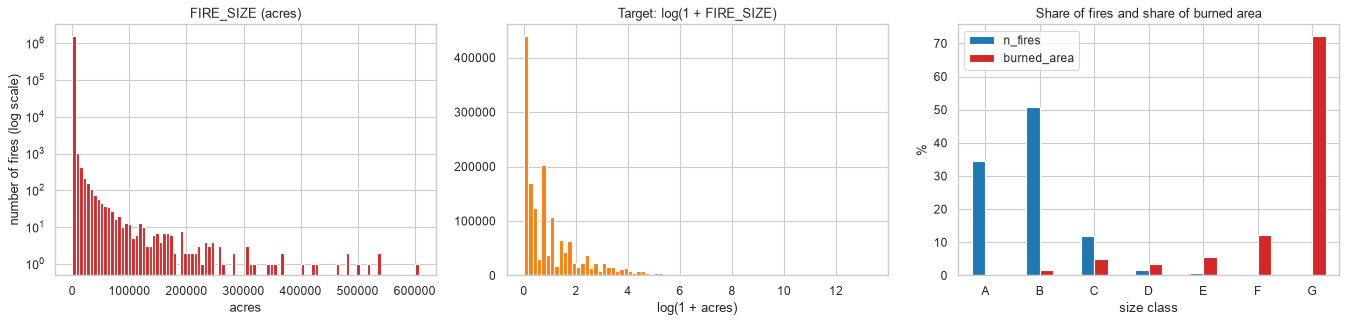

Most frequent sizes (acres): {0.1: 382115, 1.0: 186604, 0.5: 96637, 2.0: 96081}


SIZE_CLASS,A,B,C,D,E,F,G
n_fires,34.5300,50.7000,11.9600,1.5000,0.7300,0.3900,0.1800
burned_area,0.0600,1.6100,4.9800,3.5500,5.5000,12.2100,72.1000


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(train_df["FIRE_SIZE"], bins=100, color="tab:red")
axes[0].set(yscale="log", title="FIRE_SIZE (acres)", xlabel="acres", ylabel="number of fires (log scale)")
axes[1].hist(train_df[TARGET], bins=80, color="tab:orange")
axes[1].set(title="Target: log(1 + FIRE_SIZE)", xlabel="log(1 + acres)")
by_class = train_df.groupby("SIZE_CLASS")["FIRE_SIZE"].agg(n_fires="size", burned_area="sum")
share = 100 * by_class / by_class.sum()
share.plot.bar(ax=axes[2], color=["tab:blue", "tab:red"], rot=0)
axes[2].set(title="Share of fires and share of burned area", ylabel="%", xlabel="size class")
plt.tight_layout()
plt.show()
print("Most frequent sizes (acres):", train_df["FIRE_SIZE"].value_counts().head(4).to_dict())
share.T.round(2)

Observations:
- 85 % of the fires are in class A or B (less than 10 acres) but they burn only 1.7 % of the total area. The 0.18 % of fires in class G (5,000 acres or more) burn 72 % of it.
- With the raw size, a model minimising a squared error would only care about these few huge fires. After the log transform every fire counts, and errors become ratios.
- Even after the log, the distribution is very skewed and has spikes: people round the sizes they report (0.1 acre: 382,000 fires, 1 acre: 187,000, 0.5 acre: 97,000). This rounding is noise that limits how precise any model can be on small fires.

Next, missing values. Removing every row with a missing value (`dropna`) is tempting, but the containment date is missing for about half of the fires and the county for a third of them. Before doing that we check whether the missing values are random.

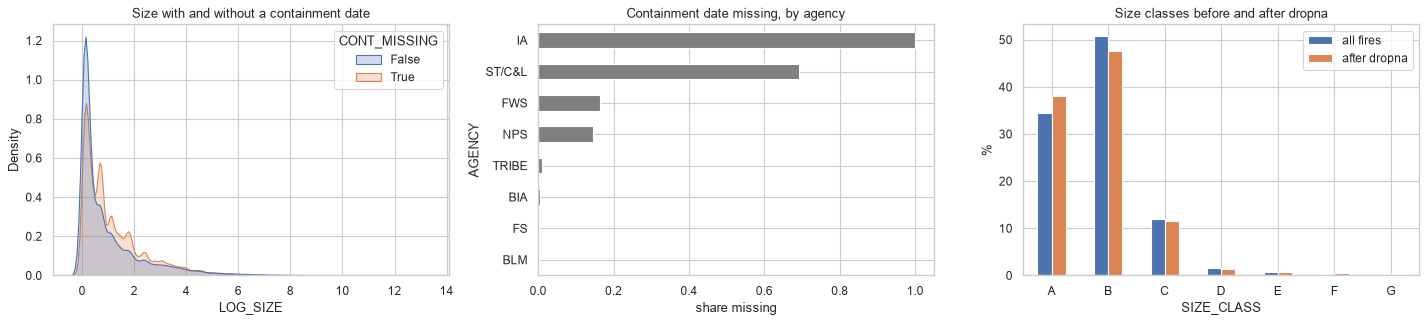

,count,mean,std,min,50%,90%,99%,max
CONT_MISSING,,,,,,,,
False,765845.0000,118.0441,3387.0348,0.0001,0.5000,17.0000,828.0000,606945.0000
True,832438.0000,22.5389,623.7506,0.0001,1.0000,17.0000,230.0000,220000.0000


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
sns.kdeplot(data=train_df.sample(200_000, random_state=RANDOM_STATE), x=TARGET, hue="CONT_MISSING",
            common_norm=False, ax=axes[0], fill=True)
axes[0].set_title("Size with and without a containment date")
missing_by_agency = train_df.groupby("AGENCY")["CONT_MISSING"].agg(["mean", "size"]).query("size > 1000")
missing_by_agency["mean"].sort_values().plot.barh(ax=axes[1], color="tab:gray")
axes[1].set(title="Containment date missing, by agency", xlabel="share missing")
pd.DataFrame({
    "all fires": train_df["SIZE_CLASS"].value_counts(normalize=True),
    "after dropna": train_df.loc[~train_df["CONT_MISSING"] & ~train_df["COUNTY_MISSING"], "SIZE_CLASS"].value_counts(normalize=True),
}).sort_index().mul(100).plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Size classes before and after dropna", ylabel="%")
plt.tight_layout()
plt.show()
train_df.groupby("CONT_MISSING")["FIRE_SIZE"].describe(percentiles=[0.5, 0.9, 0.99])

Observations:
- The containment date is missing for 52 % of the training fires, and not at random: it depends on who reported the fire (always missing for interagency reports, about 70 % for state and local services, almost never for the Forest Service or the BLM).
- Fires without a containment date are different: their median size is higher (1 acre against 0.5) but their large fires are rarer (99th percentile 230 acres against 828).
- A `dropna` would change the population we learn from: class A goes from 34.5 % to about 38 %, and mostly state and local fires are removed. So we keep every fire in scenario A, and we remember that scenario B (only fires with a duration) is a biased subset.

Time: years, months and hour of discovery.

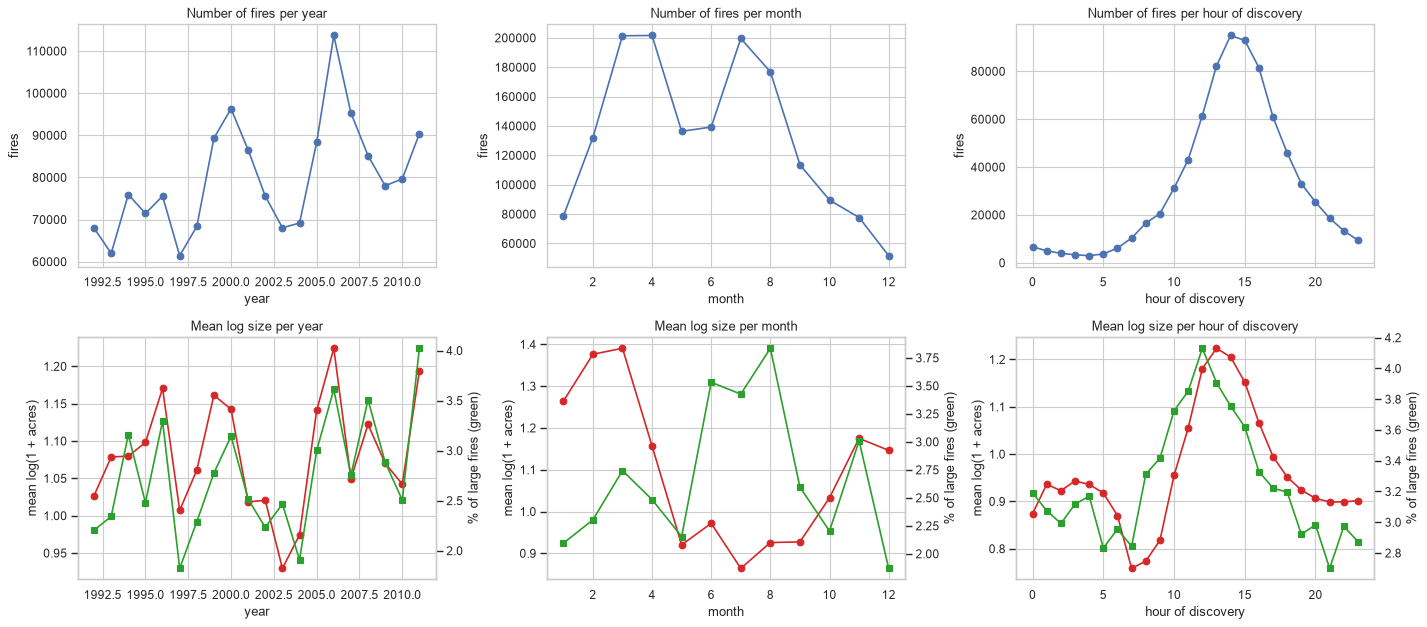

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for k, (col, label) in enumerate([("FIRE_YEAR", "year"), ("MONTH", "month"), ("DISC_HOUR", "hour of discovery")]):
    key = np.floor(train_df[col]) if col == "DISC_HOUR" else train_df[col]
    grouped = train_df.groupby(key)
    grouped.size().plot(ax=axes[0, k], marker="o")
    axes[0, k].set(title=f"Number of fires per {label}", xlabel=label, ylabel="fires")
    grouped[TARGET].mean().plot(ax=axes[1, k], marker="o", color="tab:red")
    axes[1, k].set(title=f"Mean log size per {label}", xlabel=label, ylabel="mean log(1 + acres)")
    ax2 = axes[1, k].twinx()
    (100 * grouped["FIRE_SIZE"].apply(lambda s: (s >= 100).mean())).plot(ax=ax2, marker="s", color="tab:green")
    ax2.set_ylabel("% of large fires (green)")
    ax2.grid(False)
plt.tight_layout()
plt.show()

Observations:
- Years: between 61,000 and 114,000 fires per year. The mean size goes up and down from year to year (dry years like 2006 and 2011 stand out) without a clear trend.
- Months: there are two fire seasons. March and April have many fires and the largest mean size (dry grass before the vegetation turns green, debris burning). The share of large fires is highest in June to August. So there are many medium fires in spring and fewer but bigger fires in summer.
- Hour: most fires are discovered in the early afternoon, and the fires found around 12:00 to 14:00 are the largest on average. This is when it is hottest, driest and windiest. Fires found early in the morning are the smallest.
- These effects go up and down, so a linear model will not capture them well.

Causes: how big are the fires of each cause, and when do they happen?

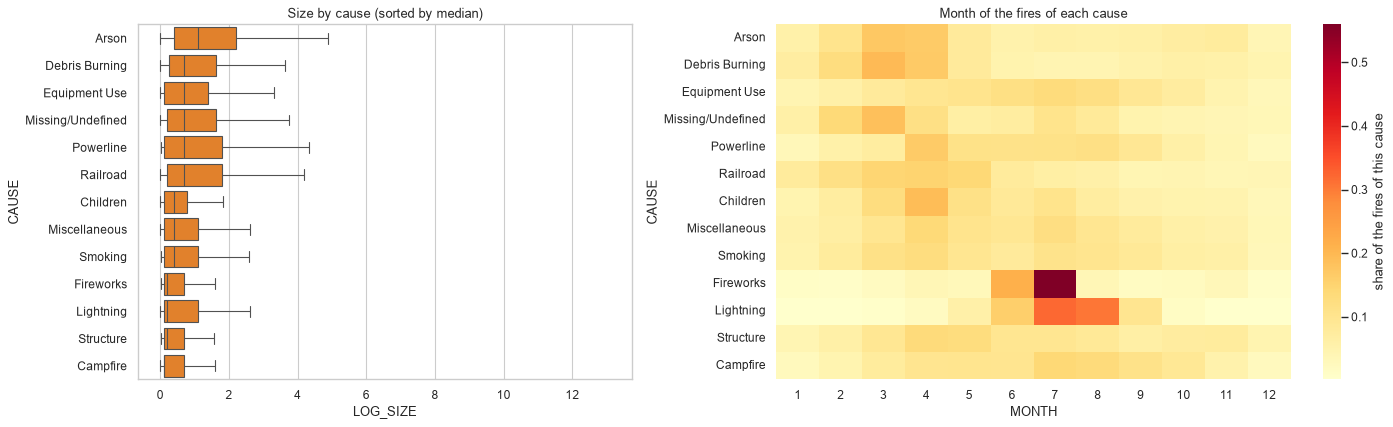

Lightning: 14.9% of fires, 29.2% of large fires, 60.4% of the burned area


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
cause_order = train_df.groupby("CAUSE")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=train_df.sample(300_000, random_state=RANDOM_STATE), y="CAUSE", x=TARGET, order=cause_order,
            ax=axes[0], fliersize=0, color="tab:orange")
axes[0].set_title("Size by cause (sorted by median)")
cause_month = pd.crosstab(train_df["CAUSE"], train_df["MONTH"], normalize="index").loc[cause_order]
sns.heatmap(cause_month, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "share of the fires of this cause"})
axes[1].set_title("Month of the fires of each cause")
plt.tight_layout()
plt.show()
lightning = train_df["CAUSE"] == "Lightning"
large = train_df["FIRE_SIZE"] >= 100
print(f"Lightning: {lightning.mean():.1%} of fires, {lightning[large].mean():.1%} of large fires, "
      f"{train_df.loc[lightning, 'FIRE_SIZE'].sum() / train_df['FIRE_SIZE'].sum():.1%} of the burned area")

Observations:
- Arson and debris burning have the highest median size; campfires, structures and fireworks the lowest.
- Lightning has one of the lowest medians, but it causes 15 % of the fires, 29 % of the large fires and 60 % of the burned area. Lightning starts fires in remote areas of the West, where they are found late and can spread. The median hides the tail.
- Each cause has its own season: fireworks almost only in July, lightning from June to August, arson and debris burning in March and April. Cause and season will matter together.

Space: where do fires happen, and where do they get big?

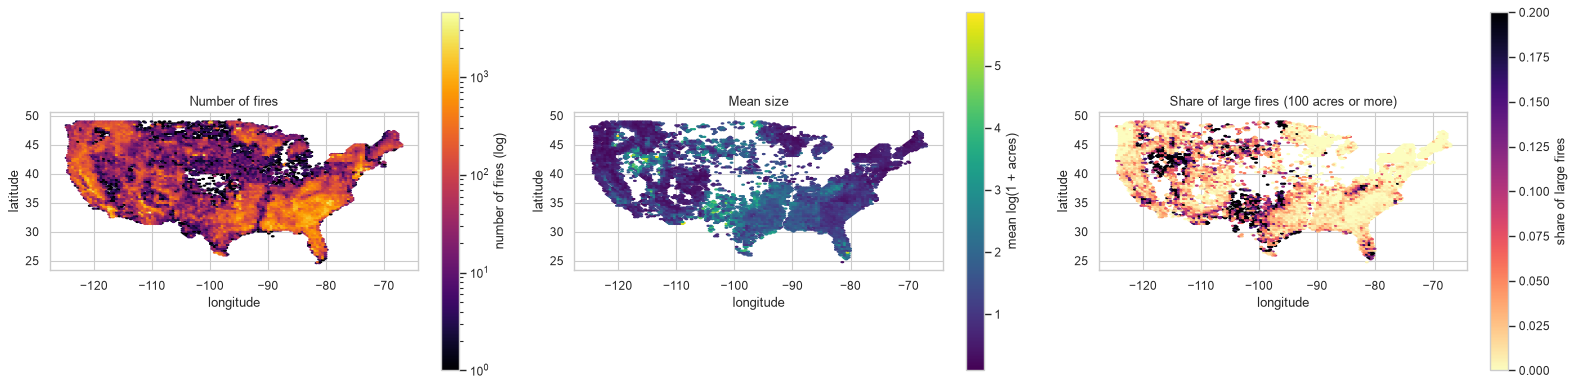

West of -100°: 33.7% of all fires, 50.8% of large fires


In [13]:
conus = train_df[train_df["LONGITUDE"].between(-125, -66) & train_df["LATITUDE"].between(24, 50)]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
hb = axes[0].hexbin(conus["LONGITUDE"], conus["LATITUDE"], gridsize=130, bins="log", cmap="inferno", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="number of fires (log)")
axes[0].set_title("Number of fires")
hb = axes[1].hexbin(conus["LONGITUDE"], conus["LATITUDE"], C=conus[TARGET], reduce_C_function=np.mean,
                    gridsize=130, cmap="viridis", mincnt=20)
fig.colorbar(hb, ax=axes[1], label="mean log(1 + acres)")
axes[1].set_title("Mean size")
hb = axes[2].hexbin(conus["LONGITUDE"], conus["LATITUDE"], C=(conus["FIRE_SIZE"] >= 100).astype(float),
                    reduce_C_function=np.mean, gridsize=130, cmap="magma_r", mincnt=20, vmax=0.2)
fig.colorbar(hb, ax=axes[2], label="share of large fires")
axes[2].set_title("Share of large fires (100 acres or more)")
for ax in axes:
    ax.set(xlabel="longitude", ylabel="latitude", aspect="equal")
plt.tight_layout()
plt.show()
west = train_df["LONGITUDE"] < -100
print(f"West of -100°: {west.mean():.1%} of all fires, {west[large].mean():.1%} of large fires")

Observations:
- Fires are most frequent in the Southeast and in California, but large fires happen mostly in the West and the Great Plains. West of -100° longitude there are 34 % of all fires but 51 % of the large ones.
- There is a clear change around -100° longitude, the limit between the dry West and the humid East. A tree can learn such a threshold, a linear model cannot.
- This is why we encode the past fire activity of each grid cell, and we expect the location to be the most useful group of features.

Duration and size (scenario B only).

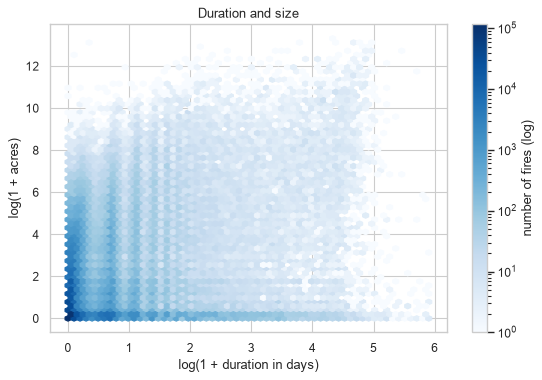

Spearman correlation duration / size: 0.142
Fires contained within one day: 88.5%


In [14]:
with_duration = train_df.dropna(subset=["DURATION_DAYS"])
fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(np.log1p(with_duration["DURATION_DAYS"]), with_duration[TARGET], gridsize=60, bins="log", cmap="Blues")
fig.colorbar(hb, label="number of fires (log)")
ax.set(xlabel="log(1 + duration in days)", ylabel="log(1 + acres)", title="Duration and size")
plt.show()
print(f"Spearman correlation duration / size: {with_duration[['DURATION_DAYS', TARGET]].corr('spearman').iloc[0, 1]:.3f}")
print(f"Fires contained within one day: {(with_duration['DURATION_DAYS'] < 1).mean():.1%}")

Observations:
- 88.5 % of the fires with a duration are contained within a day, and the Spearman correlation between duration and size is only 0.14. Some long fires stay tiny and some large grass fires are contained quickly.
- Alone, the duration is a weak predictor, but together with the location it becomes very informative (3.6). In any case it is not known at discovery, so it is only used in scenario B.

### 2.6 How strongly is each feature related to the target?
A Pearson correlation matrix is not enough here. It only measures linear relations, a few huge fires dominate it, and it does not work for categorical features, which are most of our inputs. We use three measures instead:
- Spearman correlation for numeric features. It is computed on ranks, so it is not affected by the very large fires and it detects any relation that always goes up or always goes down.
- Correlation ratio η² for categorical features: the share of the variance of the target explained by the mean of each category (0 = no link, 1 = the category gives the value).
- Mutual information for all features. It detects any kind of dependence, also the ones that go up and down (like the hour of the day). It tends to overrate features with many categories.

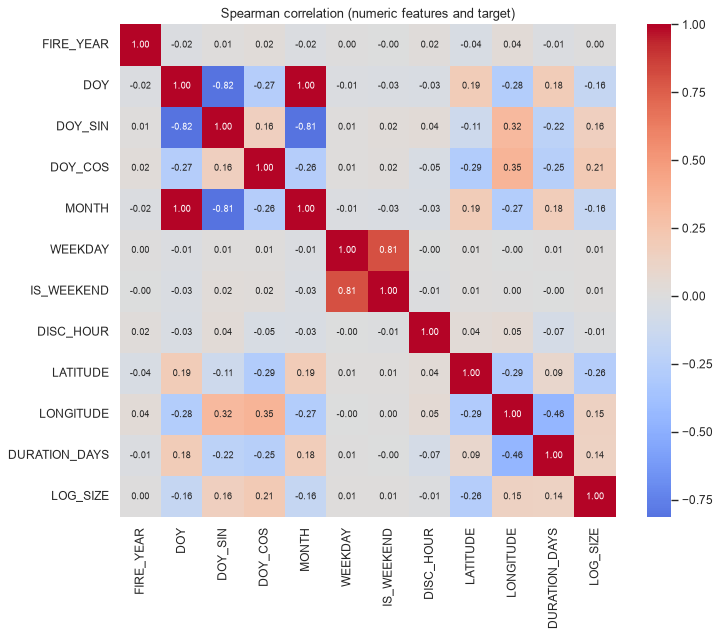

In [15]:
numeric_cols = [c for c in FEATURES_B if c not in LOW_CARD_CATEGORICAL + HIGH_CARD_CATEGORICAL]
spearman = train_df[numeric_cols + [TARGET]].sample(400_000, random_state=RANDOM_STATE).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spearman, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation (numeric features and target)")
plt.show()

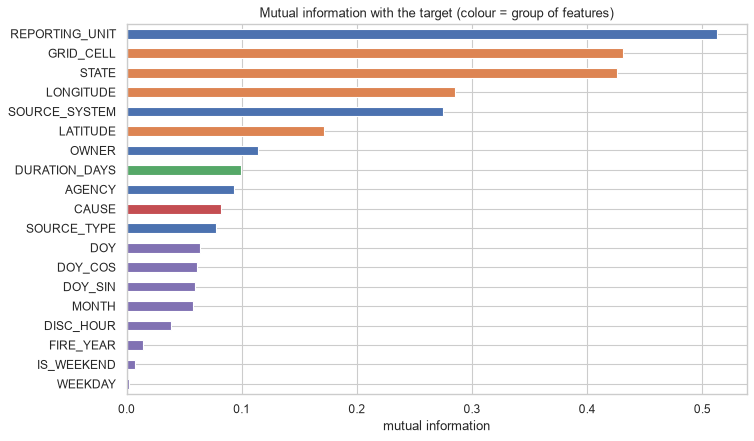

,group,spearman,eta2,mutual_info
REPORTING_UNIT,reporting,NaN,0.1715,0.5127
GRID_CELL,space,NaN,0.2120,0.4307
STATE,space,NaN,0.1146,0.4262
LONGITUDE,space,0.1467,NaN,0.2851
SOURCE_SYSTEM,reporting,NaN,0.0575,0.2744
LATITUDE,space,-0.2637,NaN,0.1716
OWNER,reporting,NaN,0.0162,0.1144
DURATION_DAYS,scenario B,0.1413,NaN,0.0998
AGENCY,reporting,NaN,0.0138,0.0933
CAUSE,cause,NaN,0.0257,0.0818


In [16]:
def correlation_ratio(categories, values):
    """eta squared: variance between the category means / total variance."""
    groups = values.groupby(categories, observed=True)
    between = (groups.size() * (groups.mean() - values.mean()) ** 2).sum()
    return between / ((values - values.mean()) ** 2).sum()


categorical_all = LOW_CARD_CATEGORICAL + HIGH_CARD_CATEGORICAL
mi_sample = train_df.sample(60_000, random_state=RANDOM_STATE)
mi_X = mi_sample[FEATURES_B].copy()
mi_X[categorical_all] = OrdinalEncoder().fit_transform(mi_X[categorical_all])
mi = mutual_info_regression(mi_X.fillna(-1), mi_sample[TARGET], random_state=RANDOM_STATE,
                            discrete_features=[c in categorical_all for c in mi_X.columns])

relevance = pd.DataFrame({
    "group": [next((g for g, fs in FEATURE_GROUPS.items() if f in fs), "scenario B") for f in FEATURES_B],
    "spearman": [spearman.loc[f, TARGET] if f in numeric_cols else np.nan for f in FEATURES_B],
    "eta2": [correlation_ratio(train_df[f], train_df[TARGET]) if f in categorical_all else np.nan for f in FEATURES_B],
    "mutual_info": mi,
}, index=FEATURES_B).sort_values("mutual_info", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
palette = dict(zip(relevance["group"].unique(), sns.color_palette()))
relevance["mutual_info"].plot.barh(ax=ax, color=[palette[g] for g in relevance["group"]])
ax.invert_yaxis()
ax.set(title="Mutual information with the target (colour = group of features)", xlabel="mutual information")
plt.show()
relevance

Observations:
- No single feature gives the size: the strongest numeric relation is with the latitude (Spearman -0.26, southern fires are bigger) and the largest η² is for the grid cell (0.21). The task is not trivial, and we see no sign of leakage left.
- The location comes first with every measure: reporting unit, grid cell, state, longitude. The mutual information of the reporting unit and the grid cell is probably overrated because they have thousands of values, so the ablation (3.6) gives a more reliable ranking.
- Some features overlap: day of year and month carry the same information, and weekday and weekend carry almost none. We keep them because trees simply ignore useless features, and the ablation tests the time group as a whole.
- The season features have low correlations but non-zero mutual information, because their effect goes up and down.

### 2.7 Encoding the features
Every transformation that learns something from the data (a median, a scaling factor, a mean per category) must learn it from the training data only, otherwise information from the validation or test years leaks into the model. We put the encoding and the model in a scikit-learn `Pipeline`: `fit` learns both on the training data, and `predict` only applies them. It also makes sure every model receives exactly the same features.

Different models need different inputs, so we build two versions:

| | Trees | Ridge and k-NN |
|---|---|---|
| numeric features | unchanged, missing values kept | missing values replaced by the median, plus a 0/1 "was missing" column, then standardised |
| categorical, few values | integer codes (gradient boosting treats them as categories) | one-hot encoding (categories with fewer than 100 fires grouped together) |
| grid cell, reporting unit | target encoding and log of the frequency | same, then standardised |

Reasons:
- Trees do not need scaling (a split like "longitude < -100" works with any unit) and handle missing values. Ridge and k-NN need features on comparable scales: k-NN measures distances between fires, and the Ridge penalty treats all coefficients the same way.
- The "was missing" column keeps the information that a value was missing, which matters here because missing values depend on who reported the fire.
- One-hot encoding for 4,000 grid cells and 1,600 reporting units would create thousands of columns, mostly for categories with very few fires. Target encoding replaces each category by the mean (log) size of the training fires in that category, which is the "usual fire size in this area". scikit-learn's `TargetEncoder` shrinks categories with few fires towards the overall mean, and during training it computes each fire's value from the other folds (5-fold cross fitting), so a fire never sees its own size.
- The frequency encoding (log of the number of training fires in the category) says how active, or how well monitored, an area is.

One detail when we compute the training score: because of the cross fitting, training fires are encoded one way during `fit` and another way during `predict`. To get a correct training score we score the training fires on the encoding that was used during `fit`.

In [17]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replaces each category by log(1 + number of training rows in that category)."""

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.counts_ = {c: X[c].value_counts() for c in self.columns_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return np.column_stack([np.log1p(X[c].map(self.counts_[c]).astype(float).fillna(0).to_numpy())
                                for c in self.columns_])

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_logfreq" for c in self.columns_])


def make_preprocessor(features, kind):
    numeric = [f for f in features if f not in LOW_CARD_CATEGORICAL + HIGH_CARD_CATEGORICAL]
    low_card = [f for f in features if f in LOW_CARD_CATEGORICAL]
    high_card = [f for f in features if f in HIGH_CARD_CATEGORICAL]
    target_encoder = TargetEncoder(target_type="auto", cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
    if kind == "tree":
        steps = [
            ("num", "passthrough", numeric),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), low_card),
            ("te", target_encoder, high_card),
            ("freq", FrequencyEncoder(), high_card),
        ]
    else:
        steps = [
            ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), low_card),
            ("te", make_pipeline(target_encoder, StandardScaler()), high_card),
            ("freq", make_pipeline(FrequencyEncoder(), StandardScaler()), high_card),
        ]
    preprocessor = ColumnTransformer([s for s in steps if s[2]])
    return preprocessor.set_output(transform="pandas") if kind == "tree" else preprocessor


def make_model(features, estimator, kind):
    return Pipeline([("prep", make_preprocessor(features, kind)), ("model", estimator)])


HGB_DEFAULTS = dict(max_iter=500, early_stopping=True, n_iter_no_change=20, random_state=RANDOM_STATE)


def make_hgb(features, classifier=False, **params):
    """Gradient boosting pipeline; the categorical features with few values are used as categories."""
    categorical = [f"cat__{f}" for f in features if f in LOW_CARD_CATEGORICAL] or None
    model_class = HistGradientBoostingClassifier if classifier else HistGradientBoostingRegressor
    return make_model(features, model_class(categorical_features=categorical, **{**HGB_DEFAULTS, **params}), "tree")


dense_preview = make_preprocessor(FEATURES_A, "dense").fit(train_sub[FEATURES_A], train_sub[TARGET])
tree_preview = make_preprocessor(FEATURES_A, "tree").fit(train_sub[FEATURES_A], train_sub[TARGET])
print(f"{len(FEATURES_A)} features -> {len(dense_preview.get_feature_names_out())} columns for Ridge and k-NN, "
      f"{len(tree_preview.get_feature_names_out())} columns for the trees")

18 features -> 140 columns for Ridge and k-NN, 20 columns for the trees


Two helper functions so that every model is evaluated the same way. `fit_and_evaluate` also returns the training score and the training time: comparing the training and validation scores tells us if a model underfits (both low) or overfits (training high, validation low).

In [18]:
def regression_report(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "class_acc": np.mean(to_size_class(np.expm1(y_true)) == to_size_class(np.expm1(np.clip(y_pred, 0, None)))),
    }


def fit_and_evaluate(name, model, train, val, features, n_train_eval=50_000):
    start = time.perf_counter()
    model.fit(train[features], train[TARGET])
    fit_seconds = time.perf_counter() - start
    # training score on the encoding seen during fit (fit_transform gives the same cross-fitted values again)
    X_seen = model["prep"].fit_transform(train[features], train[TARGET])
    rows = np.random.default_rng(RANDOM_STATE).choice(len(train), min(n_train_eval, len(train)), replace=False)
    X_seen = X_seen.iloc[rows] if hasattr(X_seen, "iloc") else X_seen[rows]
    return {"model": name, **regression_report(val[TARGET], model.predict(val[features])),
            "R2_train": r2_score(train[TARGET].iloc[rows], model["model"].predict(X_seen)),
            "fit_seconds": fit_seconds}

## 3. Training

### 3.1 Comparing models
All models are trained on the same 300,000 training fires and scored on the validation years. We go from the simplest to the most flexible, and each model tests an idea about the data:
- Mean: always predicts the training mean. Every model has to beat it.
- Ridge: linear regression with a penalty on large coefficients. Is the effect of the features simply additive?
- k-NN (k = 50): the mean size of the 50 most similar training fires. Do similar fires have similar sizes?
- Decision tree: a sequence of yes/no questions. Are there thresholds and interactions?
- Random forest: the average of many trees trained on resampled data. Does averaging remove the noise of a single tree?
- HistGradientBoosting: trees built one after the other, each one correcting the errors of the previous ones. The values of each feature are grouped into bins, which makes it fast on millions of rows. This is the reference model in the literature.

The project focuses on classical machine learning, so we do not use neural networks. We did not use kernel SVMs either, because their training time grows with the square of the number of rows.

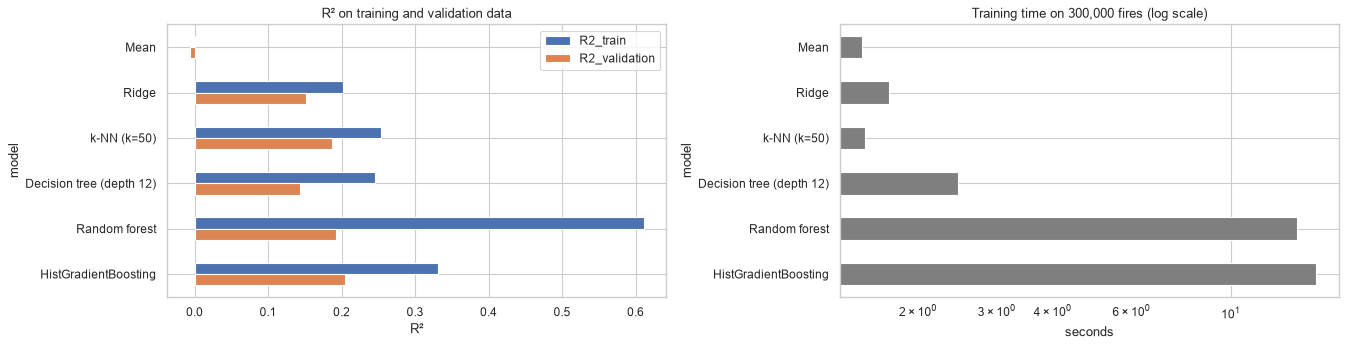

,R2,RMSE,MAE,class_acc,R2_train,fit_seconds
model,,,,,,
Mean,-0.0069,1.3325,0.9665,0.4701,-0.0000,1.5019
Ridge,0.1519,1.2229,0.8452,0.4897,0.2018,1.7226
k-NN (k=50),0.1873,1.1971,0.7887,0.4933,0.2533,1.5215
Decision tree (depth 12),0.1430,1.2293,0.8255,0.4912,0.2454,2.4572
Random forest,0.1924,1.1933,0.8120,0.4903,0.6110,14.0547
HistGradientBoosting,0.2043,1.1845,0.7829,0.5011,0.3308,15.5544


In [19]:
candidates = {
    "Mean": ("dense", DummyRegressor()),
    "Ridge": ("dense", Ridge(alpha=1.0)),
    "k-NN (k=50)": ("dense", KNeighborsRegressor(n_neighbors=50, n_jobs=-1)),
    "Decision tree (depth 12)": ("tree", DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=RANDOM_STATE)),
    "Random forest": ("tree", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5,
                                                    n_jobs=-1, random_state=RANDOM_STATE)),
}
comparison = [fit_and_evaluate(name, make_model(FEATURES_A, estimator, kind), train_sub, val_df, FEATURES_A)
              for name, (kind, estimator) in candidates.items()]
comparison.append(fit_and_evaluate("HistGradientBoosting", make_hgb(FEATURES_A), train_sub, val_df, FEATURES_A))
comparison = pd.DataFrame(comparison).set_index("model")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
comparison[["R2_train", "R2"]].rename(columns={"R2": "R2_validation"}).plot.barh(ax=axes[0])
axes[0].set(title="R² on training and validation data", xlabel="R²")
axes[0].invert_yaxis()
comparison["fit_seconds"].plot.barh(ax=axes[1], color="tab:gray", logx=True)
axes[1].set(title="Training time on 300,000 fires (log scale)", xlabel="seconds")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()
comparison

Observations:
- Every model beats the mean, but not by much: the best validation R² is 0.204 (gradient boosting). With only the information available at discovery, most of the variance of the size cannot be predicted (wind, dryness of the vegetation and how fast the crews arrive are not in the data).
- Ranking: gradient boosting 0.204, random forest 0.192, k-NN 0.187, Ridge 0.152, decision tree 0.143.
- Ridge has about 140 coefficients for 300,000 fires, so it cannot overfit, and still its training R² (0.202) is 0.05 above its validation R². This gap comes from the change between the training years and the validation years (2.4), and every model pays it.
- The random forest overfits a lot: 0.611 on the training fires against 0.192 on validation. With `min_samples_leaf=5` its trees fit groups of 5 fires and learn the noise of the target. Averaging 100 trees reduces the noise of the model, not the noise in the data.
- k-NN does well because similar fires (same place, same season, same unit) have similar sizes. But it has to compare every new fire with all the training fires, so it gets slow with 1.6 million fires, and it has only one real setting (k).
- Gradient boosting has the best score, a moderate gap between training and validation (0.331 against 0.204) and trains in about 15 seconds. It also handles missing values and categories directly. This is the model we tune.

### 3.2 Overfitting: depth of a decision tree and penalty of Ridge
The depth of a tree is the simplest way to see the bias/variance trade-off. A shallow tree is too simple (both scores low, underfitting); a deep tree learns the training fires by heart (training score goes up, validation score goes down, overfitting). We do the same with the penalty `alpha` of Ridge, and we keep the best alpha for the final Ridge in part 4.

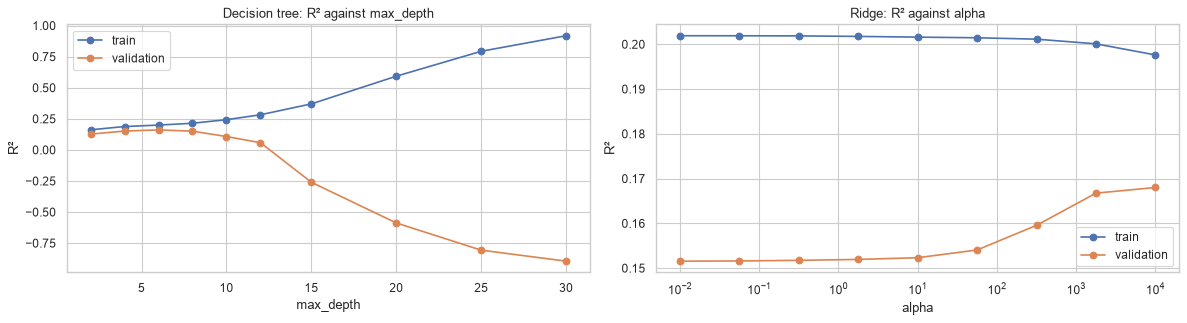

Best depth: 6 (validation R² 0.1607)
Best alpha: 10000 (validation R² 0.1680)


max_depth,2,4,6,8,10,12,15,20,25,30
train,0.1617,0.1878,0.1996,0.2144,0.2430,0.2826,0.3701,0.5928,0.7933,0.9183
validation,0.1270,0.1516,0.1607,0.1508,0.1077,0.0578,-0.2603,-0.5877,-0.8066,-0.8950


In [20]:
depth_scores = []
for depth in [2, 4, 6, 8, 10, 12, 15, 20, 25, 30]:
    tree = make_model(FEATURES_A, DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE), "tree")
    result = fit_and_evaluate(f"depth {depth}", tree, train_sub, val_df, FEATURES_A)
    depth_scores.append({"max_depth": depth, "train": result["R2_train"], "validation": result["R2"]})
depth_scores = pd.DataFrame(depth_scores).set_index("max_depth")

ridge_scores = []
for alpha in np.logspace(-2, 4, 9):
    result = fit_and_evaluate(f"alpha {alpha}", make_model(FEATURES_A, Ridge(alpha=alpha), "dense"), train_sub, val_df, FEATURES_A)
    ridge_scores.append({"alpha": alpha, "train": result["R2_train"], "validation": result["R2"]})
ridge_scores = pd.DataFrame(ridge_scores).set_index("alpha")
BEST_ALPHA = ridge_scores["validation"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
depth_scores.plot(ax=axes[0], marker="o")
axes[0].set(title="Decision tree: R² against max_depth", ylabel="R²")
ridge_scores.plot(ax=axes[1], marker="o", logx=True)
axes[1].set(title="Ridge: R² against alpha", ylabel="R²")
plt.tight_layout()
plt.show()
print(f"Best depth: {depth_scores['validation'].idxmax()} (validation R² {depth_scores['validation'].max():.4f})")
print(f"Best alpha: {BEST_ALPHA:.0f} (validation R² {ridge_scores['validation'].max():.4f})")
depth_scores.T

Observations:
- Decision tree: up to depth 6 both scores go up together (the tree is too simple, underfitting). The best validation R² is at depth 6 (0.161). After that the training R² keeps rising (0.92 at depth 30) while the validation R² falls and becomes negative (0.06 at depth 12, -0.26 at depth 15, -0.90 at depth 30). A deep tree isolates small groups of fires and predicts their exact sizes, which is noise for new fires. This is overfitting.
- Ridge: the best alpha is 10,000, the largest value we tried, but the gain is small (0.152 with alpha = 1, 0.168 with alpha = 10,000). Ridge is mostly limited by its bias: it can only add up effects, without thresholds or interactions.
- What we take from this for gradient boosting: the model must not be allowed to follow individual fires, so the search below includes large values of `min_samples_leaf` and of the L2 penalty.

### 3.3 Tuning gradient boosting
Gradient boosting was the best model in 3.1, so we tune it. We use a random search over five hyperparameters: with five of them a full grid would be huge, and a random search tries more different values of each hyperparameter for the same number of fits (Bergstra and Bengio, 2012).

| Hyperparameter | What it controls | Range |
|---|---|---|
| `learning_rate` | how much each new tree corrects the previous ones. Smaller is smoother but needs more trees | 0.03 to 0.3 (log scale) |
| `max_leaf_nodes` | size of each tree, so how many interactions it can learn | 15 to 511 |
| `min_samples_leaf` | minimum number of fires in a leaf | 10 to 2000 |
| `l2_regularization` | penalty that shrinks the values in the leaves | 0.001 to 10 (log scale) |
| `max_features` | share of the features tried at each split | 0.3 to 1 |

Each candidate is trained on the 300,000 training fires and scored on the validation years (`PredefinedSplit`). We do not use K-fold cross validation because it would mix the years, which is the random split we want to avoid. The number of trees (at most 500) is chosen by early stopping: 10 % of the training data is kept aside inside the model and training stops when 20 new trees do not improve it.

Search done in 1006 s
Best: {'l2_regularization': np.float64(0.0634), 'learning_rate': np.float64(0.0309), 'max_features': 0.3, 'max_leaf_nodes': 330, 'min_samples_leaf': 500}


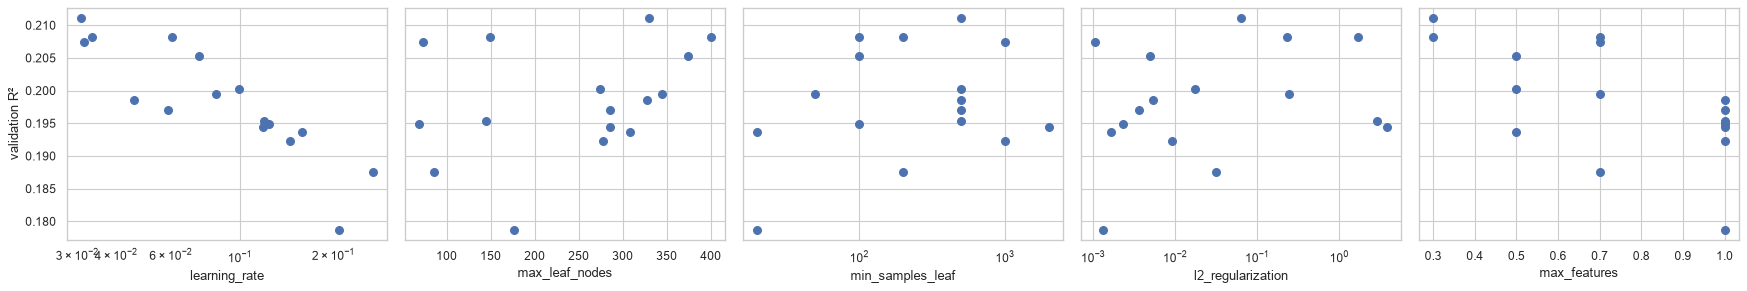

,l2_regularization,learning_rate,max_features,max_leaf_nodes,min_samples_leaf,val_R2
9,0.0634,0.0309,0.3000,330,500,0.2110
8,0.2342,0.0334,0.7000,149,200,0.2082
10,1.7123,0.0605,0.3000,400,100,0.2081
5,0.0011,0.0316,0.7000,73,1000,0.2075
12,0.0049,0.0738,0.5000,374,100,0.2053
13,0.0177,0.0994,0.5000,274,500,0.2002
1,0.2440,0.0837,0.7000,345,50,0.1995
4,0.0053,0.0458,1.0000,328,500,0.1985


In [21]:
search_data = pd.concat([train_sub, val_df])
validation_fold = PredefinedSplit(np.r_[np.full(len(train_sub), -1), np.zeros(len(val_df))])
param_distributions = {
    "model__learning_rate": loguniform(0.03, 0.3),
    "model__max_leaf_nodes": randint(15, 512),
    "model__min_samples_leaf": [10, 20, 50, 100, 200, 500, 1000, 2000],
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_features": [0.3, 0.5, 0.7, 1.0],
}
search = RandomizedSearchCV(make_hgb(FEATURES_A), param_distributions, n_iter=16, cv=validation_fold, scoring="r2",
                            refit=False, random_state=RANDOM_STATE)
start = time.perf_counter()
search.fit(search_data[FEATURES_A], search_data[TARGET])
print(f"Search done in {time.perf_counter() - start:.0f} s")

search_results = pd.DataFrame(search.cv_results_["params"]).rename(columns=lambda c: c.replace("model__", ""))
search_results["val_R2"] = search.cv_results_["mean_test_score"]
search_results = search_results.sort_values("val_R2", ascending=False)
BEST_HGB_PARAMS = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best:", {k: round(v, 4) if isinstance(v, float) else v for k, v in BEST_HGB_PARAMS.items()})

fig, axes = plt.subplots(1, 5, figsize=(22, 3.8), sharey=True)
for ax, param in zip(axes, ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_features"]):
    ax.scatter(search_results[param], search_results["val_R2"], s=50)
    ax.set(xlabel=param, xscale="log" if param in ("learning_rate", "l2_regularization", "min_samples_leaf") else "linear")
axes[0].set_ylabel("validation R²")
plt.tight_layout()
plt.show()
search_results.head(8)

Observations:
- Best candidate: `learning_rate` 0.031, `max_leaf_nodes` 330, `min_samples_leaf` 500, `l2_regularization` 0.063 and `max_features` 0.3, with a validation R² of 0.211 (0.204 with the default settings).
- The clearest effect is the learning rate: the smaller it is, the better the score. Using only part of the features at each split (`max_features` below 1) also helps. The other hyperparameters have no clear effect in these ranges.
- The best learning rate is at the bottom of the range and the best model uses all 500 trees, so a smaller learning rate with more trees might still gain a little, but it would take much longer to train.

### 3.4 Learning curve
With the tuned hyperparameters we train on more and more fires, up to the 1.6 million training fires. If the validation score still goes up at the end, more data would help. If it flattens, the limit is the information contained in the features.

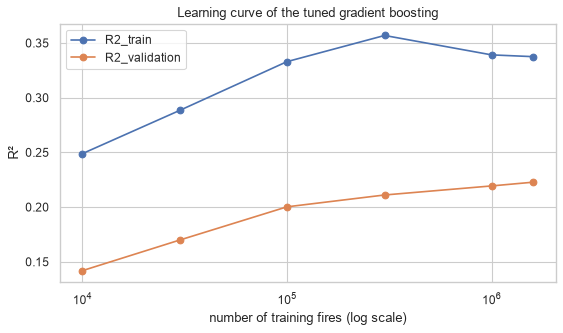

,R2,R2_train,fit_seconds,n_trees
n_train,,,,
10000,0.1419,0.2488,5.4354,341
30000,0.1699,0.2885,17.1880,362
100000,0.2002,0.3329,77.6184,500
300000,0.2110,0.3569,200.5184,500
1000000,0.2193,0.3391,231.6612,500
1598283,0.2227,0.3375,252.6061,500


In [22]:
learning_curve = []
for n in [10_000, 30_000, 100_000, 300_000, 1_000_000, len(train_df)]:
    part = train_df.sample(n, random_state=RANDOM_STATE) if n < len(train_df) else train_df
    model_n = make_hgb(FEATURES_A, **BEST_HGB_PARAMS)
    learning_curve.append({"n_train": n, **fit_and_evaluate(str(n), model_n, part, val_df, FEATURES_A),
                           "n_trees": model_n["model"].n_iter_})
learning_curve = pd.DataFrame(learning_curve).set_index("n_train")
hgb_train_only = model_n  # tuned model trained on all the 1992-2011 fires, used again in part 4

fig, ax = plt.subplots(figsize=(8, 4.2))
learning_curve[["R2_train", "R2"]].rename(columns={"R2": "R2_validation"}).plot(ax=ax, marker="o", logx=True)
ax.set(title="Learning curve of the tuned gradient boosting", xlabel="number of training fires (log scale)", ylabel="R²")
plt.show()
learning_curve[["R2", "R2_train", "fit_seconds", "n_trees"]]

Observations:
- The validation R² grows quickly at first (0.142 with 10,000 fires, 0.200 with 100,000) and then flattens: 0.211 with 300,000, 0.219 with 1 million and 0.223 with all 1.6 million fires.
- The training R² stays between 0.25 and 0.36, far from 1: leaves of at least 500 fires stop the model from learning individual fires. The gap between training and validation gets smaller when we add data.
- The curve is almost flat at the end, so more fires of the same kind will not help much. The limit is the information in the features. To do better we would need new information, for example the weather at discovery.
- It also shows that the 300,000 sample used in part 3 was a reasonable choice: it already reaches 95 % of the score of the full training set.

### 3.5 PCA
After one-hot encoding, Ridge and k-NN receive 140 columns, and many of them are correlated (day of year, month, sine and cosine; four ways of describing the location). PCA replaces these columns by new uncorrelated axes, ordered by how much of the variance of the data they keep. Keeping only the first ones could remove noise and help a linear model.

PCA only looks at the features, never at the target. The directions where the features vary the most are not necessarily the ones that predict the size. We check three things: how many components are needed, whether the first two separate small and large fires, and whether training on the components helps Ridge or gradient boosting.

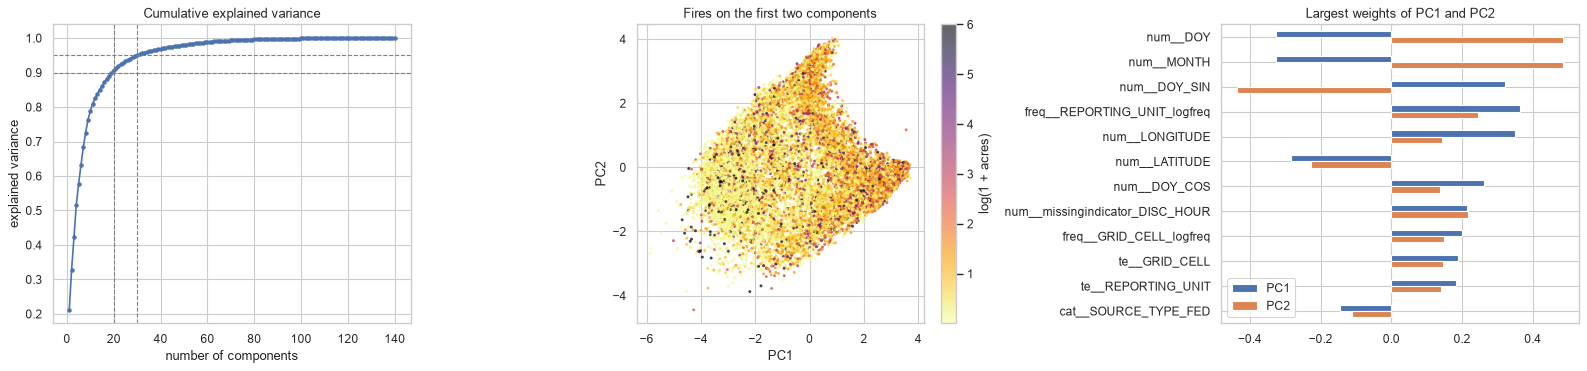

20 components keep 90 % of the variance and 30 keep 95 % (out of 140 columns)


In [23]:
pca_prep = make_preprocessor(FEATURES_A, "dense")
X_dense_train = pca_prep.fit_transform(train_sub[FEATURES_A], train_sub[TARGET])
X_dense_val = pca_prep.transform(val_df[FEATURES_A])
pca = PCA(random_state=RANDOM_STATE).fit(X_dense_train)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n_90, n_95 = np.searchsorted(cumulative, 0.90) + 1, np.searchsorted(cumulative, 0.95) + 1

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative, marker=".")
for n, level in [(n_90, 0.90), (n_95, 0.95)]:
    axes[0].axhline(level, ls="--", color="gray", lw=1)
    axes[0].axvline(n, ls="--", color="gray", lw=1)
axes[0].set(title="Cumulative explained variance", xlabel="number of components", ylabel="explained variance")
projected = pca.transform(X_dense_train[:20_000])[:, :2]
points = axes[1].scatter(projected[:, 0], projected[:, 1], c=train_sub[TARGET].iloc[:20_000], cmap="inferno_r", s=3, alpha=0.6, vmax=6)
fig.colorbar(points, ax=axes[1], label="log(1 + acres)")
axes[1].set(title="Fires on the first two components", xlabel="PC1", ylabel="PC2")
loadings = pd.DataFrame(pca.components_[:2].T, index=pca_prep.get_feature_names_out(), columns=["PC1", "PC2"])
loadings.loc[loadings.abs().max(axis=1).sort_values(ascending=False).index[:12]].plot.barh(ax=axes[2])
axes[2].invert_yaxis()
axes[2].set(title="Largest weights of PC1 and PC2")
plt.tight_layout()
plt.show()
print(f"{n_90} components keep 90 % of the variance and {n_95} keep 95 % (out of {X_dense_train.shape[1]} columns)")

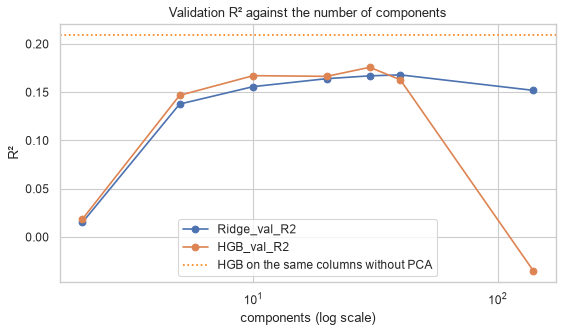

Gradient boosting on the same 140 columns without PCA: validation R² = 0.2087


,explained_variance,Ridge_val_R2,HGB_val_R2
n_components,,,
2,0.3282,0.0150,0.0184
5,0.5777,0.1377,0.1467
10,0.7891,0.1557,0.1671
20,0.9065,0.1640,0.1664
30,0.9504,0.1669,0.1758
40,0.9688,0.1679,0.1628
140,1.0000,0.1519,-0.0349


In [24]:
pca_results = []
for k in sorted({2, 5, 10, 20, 40, n_95, X_dense_train.shape[1]}):
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE).fit(X_dense_train)
    Z_train, Z_val = pca_k.transform(X_dense_train), pca_k.transform(X_dense_val)
    pca_results.append({
        "n_components": k, "explained_variance": pca_k.explained_variance_ratio_.sum(),
        "Ridge_val_R2": r2_score(val_df[TARGET], Ridge().fit(Z_train, train_sub[TARGET]).predict(Z_val)),
        "HGB_val_R2": r2_score(val_df[TARGET], HistGradientBoostingRegressor(**HGB_DEFAULTS).fit(Z_train, train_sub[TARGET]).predict(Z_val)),
    })
pca_results = pd.DataFrame(pca_results).set_index("n_components")
hgb_no_pca = r2_score(val_df[TARGET], HistGradientBoostingRegressor(**HGB_DEFAULTS).fit(X_dense_train, train_sub[TARGET]).predict(X_dense_val))

fig, ax = plt.subplots(figsize=(8, 4.2))
pca_results[["Ridge_val_R2", "HGB_val_R2"]].plot(ax=ax, marker="o", logx=True)
ax.axhline(hgb_no_pca, color="tab:orange", ls=":", label="HGB on the same columns without PCA")
ax.set(title="Validation R² against the number of components", xlabel="components (log scale)", ylabel="R²")
ax.legend()
plt.show()
print(f"Gradient boosting on the same {X_dense_train.shape[1]} columns without PCA: validation R² = {hgb_no_pca:.4f}")
pca_results

Observations:
- The 140 columns are very redundant: 20 components keep 90 % of the variance and 30 keep 95 %.
- The first two components do not separate small and large fires (the dark points are spread everywhere). They are driven by the season (day of year, month) and by the location and reporting activity (longitude, latitude, frequency of the reporting unit). This is the limit of PCA: it keeps the directions where the features vary the most, which says nothing about the target.
- For Ridge, PCA works like a regularisation: with 30 to 40 components it gets 0.167 to 0.168, better than Ridge on the 140 columns with alpha = 1 (0.152) and about the same as the best alpha in 3.2.
- For gradient boosting, PCA hurts. Its best score is 0.176 with 30 components, against 0.209 on the same columns without PCA, and with all 140 components (a simple rotation that loses no information) the R² even becomes negative (-0.035). Trees split on one feature at a time, and a rotation mixes meaningful axes like the longitude into combinations that trees approximate badly.
- So we do not use PCA in the final model.

### 3.6 Ablation study
Which groups of features carry the information? Looking at features one by one is misleading when they overlap: if we remove the latitude, the grid cell still tells the model where the fire is. So we work with whole groups and retrain the tuned model each time:
- without one group: the drop in R² is what only this group brings
- with only one group: the R² is what this group can explain alone

Then, for scenario B, we measure what the duration adds, on the fires that have a valid duration.

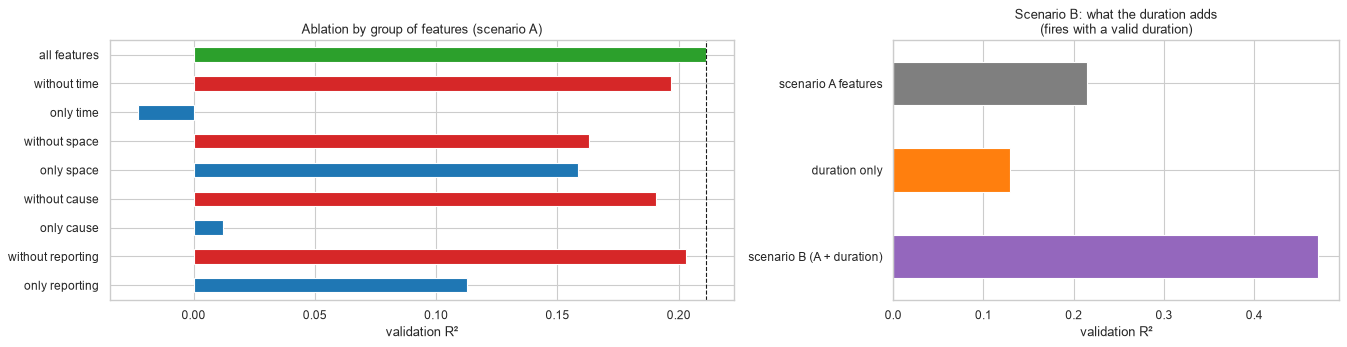

,val_R2,difference
all features,0.2110,0.0000
without time,0.1970,-0.0141
only time,-0.0229,-0.2340
without space,0.1632,-0.0478
only space,0.1583,-0.0527
without cause,0.1906,-0.0204
only cause,0.0122,-0.1988
without reporting,0.2029,-0.0081
only reporting,0.1125,-0.0985


,val_R2
scenario A features,0.2148
duration only,0.1291
scenario B (A + duration),0.4705


In [25]:
def hgb_val_r2(features, train, val):
    model = make_hgb(features, **BEST_HGB_PARAMS).fit(train[features], train[TARGET])
    return r2_score(val[TARGET], model.predict(val[features]))


all_r2 = hgb_val_r2(FEATURES_A, train_sub, val_df)
ablation = {"all features": all_r2}
for group, group_features in FEATURE_GROUPS.items():
    ablation[f"without {group}"] = hgb_val_r2([f for f in FEATURES_A if f not in group_features], train_sub, val_df)
    ablation[f"only {group}"] = hgb_val_r2(group_features, train_sub, val_df)
ablation = pd.DataFrame({"val_R2": ablation})
ablation["difference"] = ablation["val_R2"] - all_r2

train_b = train_df.dropna(subset=["DURATION_DAYS"]).sample(300_000, random_state=RANDOM_STATE)
val_b = val_df.dropna(subset=["DURATION_DAYS"])
scenario_b = pd.DataFrame({"val_R2": {
    "scenario A features": hgb_val_r2(FEATURES_A, train_b, val_b),
    "duration only": hgb_val_r2(["DURATION_DAYS"], train_b, val_b),
    "scenario B (A + duration)": hgb_val_r2(FEATURES_B, train_b, val_b),
}})

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
colors = ["tab:green" if e.startswith("all") else "tab:red" if e.startswith("without") else "tab:blue" for e in ablation.index]
ablation["val_R2"].plot.barh(ax=axes[0], color=colors)
axes[0].axvline(all_r2, color="k", ls="--", lw=1)
axes[0].invert_yaxis()
axes[0].set(title="Ablation by group of features (scenario A)", xlabel="validation R²")
scenario_b["val_R2"].plot.barh(ax=axes[1], color=["tab:gray", "tab:orange", "tab:purple"])
axes[1].invert_yaxis()
axes[1].set(title="Scenario B: what the duration adds\n(fires with a valid duration)", xlabel="validation R²")
plt.tight_layout()
plt.show()
display(ablation)
scenario_b

Observations (all features: validation R² 0.211):

| group | without it | only it |
|---|---|---|
| space (latitude, longitude, state, grid cell) | 0.163 (-0.048) | 0.158 |
| cause | 0.191 (-0.020) | 0.012 |
| time (year, season, hour, weekday) | 0.197 (-0.014) | -0.023 |
| reporting (owner, agency, source, unit) | 0.203 (-0.008) | 0.113 |

- Space is the most important group, both alone and in what it brings that the others do not.
- Reporting is good alone (0.113) but mostly redundant with space, because a reporting unit is a place. Removing it costs only 0.008.
- The cause alone predicts almost nothing (0.012), but removing it costs 0.020: its effect depends on the place and the season (a lightning fire in Nevada in August is not the same as one in Florida).
- Time alone is useless on new years, but it helps together with the other groups (seasons and hours do not have the same effect everywhere).
- Scenario B: on fires with a duration, the scenario A features give 0.215, the duration alone 0.129, and both together 0.471, more than twice as much. But the duration is only known after the fire, so scenario B explains the size afterwards rather than predicting it.

## 4. Evaluation on the test set (2014-2015)

### 4.1 Final scores
The final model is the tuned gradient boosting, scenario A. All our choices are now fixed, so we retrain it on all fires from 1992 to 2013 (training and validation years): the validation years are the most recent ones before the test period and the data changes over time (2.4), so they are useful to learn from. For comparison, the mean and Ridge (with the best alpha from 3.2) are trained and evaluated in exactly the same way. This is the only time we use the test set.

In [26]:
train_val_df = pd.concat([train_df, val_df])
final_models = {
    "Mean": make_model(FEATURES_A, DummyRegressor(), "dense"),
    "Ridge": make_model(FEATURES_A, Ridge(alpha=BEST_ALPHA), "dense"),
    "Gradient boosting (tuned)": make_hgb(FEATURES_A, **BEST_HGB_PARAMS),
}
test_results = {}
for name, model in final_models.items():
    model.fit(train_val_df[FEATURES_A], train_val_df[TARGET])
    test_results[name] = regression_report(test_df[TARGET], model.predict(test_df[FEATURES_A]))
final_model = final_models["Gradient boosting (tuned)"]
test_pred = final_model.predict(test_df[FEATURES_A])
test_results = pd.DataFrame(test_results).T
test_results["always_class_B_acc"] = (test_df["SIZE_CLASS"] == "B").mean()
test_results

,R2,RMSE,MAE,class_acc,always_class_B_acc
Mean,-0.0061,1.3300,0.9705,0.4495,0.4495
Ridge,0.1588,1.2161,0.8316,0.4794,0.4495
Gradient boosting (tuned),0.2525,1.1464,0.7617,0.4950,0.4495


In [27]:
abs_error = (test_pred - test_df[TARGET]).abs()
mean_error = (train_val_df[TARGET].mean() - test_df[TARGET]).abs()
pd.DataFrame({
    "final model": [np.median(abs_error), np.mean(abs_error <= np.log(2)), np.mean(abs_error <= np.log(10))],
    "mean": [np.median(mean_error), np.mean(mean_error <= np.log(2)), np.mean(mean_error <= np.log(10))],
}, index=["median error (log)", "share within a factor 2", "share within a factor 10"])

,final model,mean
median error (log),0.5200,0.8974
share within a factor 2,0.6192,0.3562
share within a factor 10,0.9501,0.9351


Observations:
- Final model on the test years: R² = 0.253 (RMSE 1.146, MAE 0.762). Ridge gets 0.159 and the mean -0.006.
- The test score is higher than the validation score of 3.4 (0.223). The final model was trained with two more recent years (2012-2013), and the next section shows that the model trained only on 1992-2011 gets 0.23 on 2014 and 0.21 on 2015, so these recent years help.
- The size-class accuracy is 49.5 %, only 4.5 points above always answering class B (45.0 %). This is why we do not use the class accuracy as our main metric.
- In practice: the median error is 0.52 in log (a factor of about 1.7) against 0.90 for the mean, and 62 % of the fires are predicted within a factor 2 of their true size, against 36 % for the mean. Within a factor 10 both are above 93 %, because most fires are small anyway.

### 4.2 Where is the model wrong?

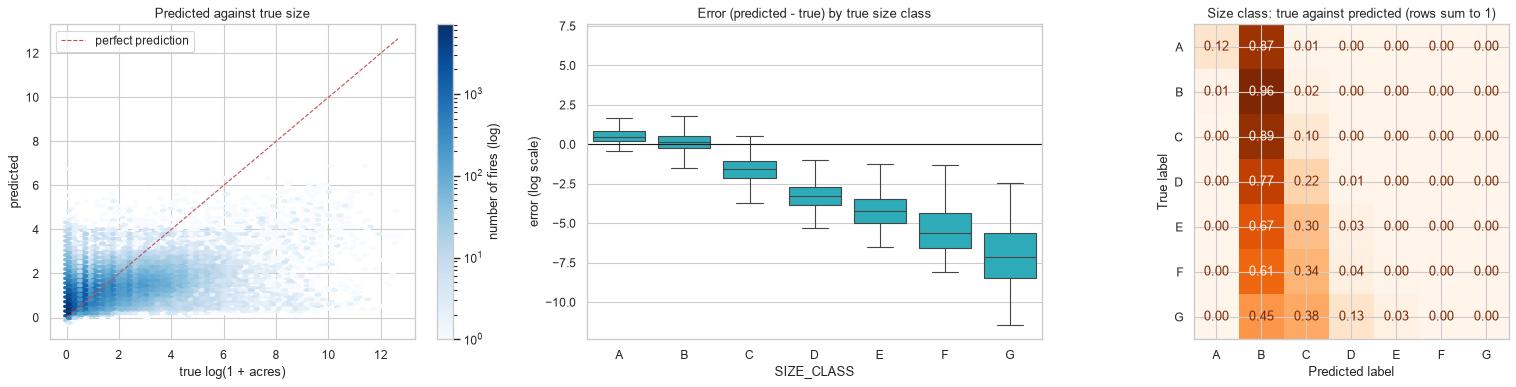

,n_fires,MAE,mean_error
SIZE_CLASS,,,
A,59600,0.5928,0.5907
B,63849,0.5240,0.1506
C,14926,1.6249,-1.5950
D,1914,3.2182,-3.2155
E,871,4.1590,-4.1580
F,491,5.4332,-5.4332
G,382,7.0259,-7.0259


In [28]:
test_eval = test_df[[TARGET, "SIZE_CLASS"]].assign(pred=test_pred, error=test_pred - test_df[TARGET])
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
hb = axes[0].hexbin(test_eval[TARGET], test_eval["pred"], gridsize=60, bins="log", cmap="Blues")
axes[0].plot([0, test_eval[TARGET].max()], [0, test_eval[TARGET].max()], "r--", lw=1, label="perfect prediction")
axes[0].set(xlabel="true log(1 + acres)", ylabel="predicted", title="Predicted against true size")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="number of fires (log)")
sns.boxplot(data=test_eval, x="SIZE_CLASS", y="error", order=list("ABCDEFG"), ax=axes[1], fliersize=0, color="tab:cyan")
axes[1].axhline(0, color="k", lw=1)
axes[1].set(title="Error (predicted - true) by true size class", ylabel="error (log scale)")
ConfusionMatrixDisplay.from_predictions(test_eval["SIZE_CLASS"], to_size_class(np.expm1(np.clip(test_pred, 0, None))),
                                        labels=list("ABCDEFG"), normalize="true", values_format=".2f", ax=axes[2],
                                        cmap="Oranges", colorbar=False)
axes[2].set(title="Size class: true against predicted (rows sum to 1)")
plt.tight_layout()
plt.show()
test_eval.groupby("SIZE_CLASS").agg(n_fires=("error", "size"), MAE=("error", lambda e: e.abs().mean()),
                                    mean_error=("error", "mean"))

Observations:
- The predictions stay between 0 and about 6 while the true values go up to 13. Small fires are a bit overestimated (+0.59 for class A), class B is about right, and large fires are more and more underestimated: -3.2 for class D and -7.0 for class G, which is a factor of about 1,000.
- In the confusion matrix almost everything is predicted as class B: 96 % of B fires are right, but only 10 % of C fires, and D to G are almost never predicted.
- This is regression towards the mean, and it is what a model trained with a squared error does on a noisy target: it predicts the average size of the fires that look like this one. At discovery a future huge fire looks like many small fires, so its prediction is never extreme. To find large fires we need a dedicated classifier (4.5).

### 4.3 Does the score change from one year to the next?
The data changes over time (2.4), so we look at the score year by year, with the tuned model trained on 1992-2011 only (from 3.4). Kansas is shown separately because its number of reported fires jumps in 2015.

In [29]:
yearly = []
for year in range(2012, 2016):
    part = df[df["FIRE_YEAR"] == year]
    not_kansas = part[part["STATE"] != "KS"]
    yearly.append({"year": year, "n_fires": len(part), "kansas_fires": (part["STATE"] == "KS").sum(),
                   "R2": r2_score(part[TARGET], hgb_train_only.predict(part[FEATURES_A])),
                   "R2_without_kansas": r2_score(not_kansas[TARGET], hgb_train_only.predict(not_kansas[FEATURES_A]))})
yearly = pd.DataFrame(yearly).set_index("year")
display(yearly)

kansas = df["STATE"] == "KS"
print("Kansas fires per year and source system:")
pd.crosstab(df.loc[kansas, "FIRE_YEAR"], df.loc[kansas, "SOURCE_SYSTEM"]).loc[2008:]

,n_fires,kansas_fires,R2,R2_without_kansas
year,,,,
2012,72658,46,0.2329,0.2326
2013,64734,13,0.1999,0.1997
2014,67652,32,0.2299,0.2291
2015,74381,5875,0.2092,0.2604


Kansas fires per year and source system:


SOURCE_SYSTEM,DOI-WFMI,FA-NFIRS,FS-FIRESTAT,FWS-FMIS,ST-NASF
FIRE_YEAR,,,,,
2008,7,35,6,30,0
2009,13,0,1,27,0
2010,5,0,7,13,0
2011,13,0,3,36,0
2012,15,0,1,30,0
2013,3,0,3,7,0
2014,12,0,0,20,0
2015,30,0,1,10,5834


In [30]:
not_kansas_test = test_df["STATE"] != "KS"
pd.DataFrame({
    name: {"test R2": test_results.loc[name, "R2"],
           "test R2 without Kansas": r2_score(test_df.loc[not_kansas_test, TARGET],
                                              model.predict(test_df.loc[not_kansas_test, FEATURES_A]))}
    for name, model in final_models.items()
}).T

,test R2,test R2 without Kansas
Mean,-0.0061,-0.0071
Ridge,0.1588,0.1985
Gradient boosting (tuned),0.2525,0.2717


Observations:
- The model trained on 1992-2011 gets about the same score every year: 0.233 in 2012, 0.200 in 2013, 0.230 in 2014 and 0.209 in 2015. There is no general loss of quality over time.
- 2015 is a bit lower because of Kansas. Kansas has between 13 and 46 fires per year in 2012-2014, but 5,875 in 2015, and 5,834 of them come from a new source, the Kansas Forest Service (`ST-NASF`), which never appears before. Kansas did not have 100 times more fires; a new agency started sending its fires to the database. The model has never seen this source or its reporting unit. Without Kansas, the 2015 score is 0.260.
- On the whole test set, removing Kansas would give 0.272 instead of 0.253 for gradient boosting, and 0.199 instead of 0.159 for Ridge. We still report 0.253: removing Kansas after looking at the test results would mean choosing our test data.
- In practice a model like this one should be monitored: when a new source starts reporting, the number of records per state and per source changes suddenly, which is easy to detect.

### 4.4 Which features does the model use?
Permutation importance: we shuffle the values of one feature in the test set and measure how much the R² drops. It works on the raw features, so it is easy to read, and unlike the importance built into trees it does not favour features with many values.

We also draw partial dependence plots: the average prediction when one feature changes and the others stay as they are. A good score is not enough, we want to check that what the model learned makes sense physically and agrees with the exploration.

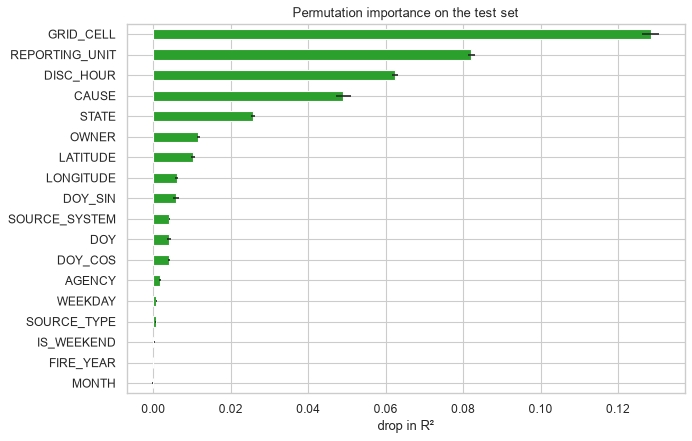

In [31]:
importance_sample = test_df.sample(40_000, random_state=RANDOM_STATE)
perm = permutation_importance(final_model, importance_sample[FEATURES_A], importance_sample[TARGET], scoring="r2",
                              n_repeats=5, random_state=RANDOM_STATE)
perm_importance = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATURES_A).sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 6))
perm_importance["mean"].plot.barh(xerr=perm_importance["std"], ax=ax, color="tab:green")
ax.set(title="Permutation importance on the test set", xlabel="drop in R²")
plt.show()

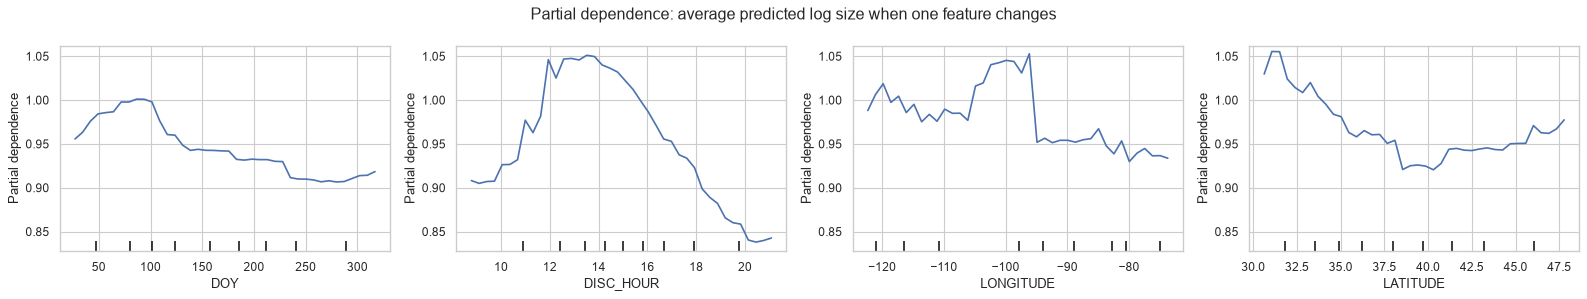

,mean,std
GRID_CELL,0.1284,0.0022
REPORTING_UNIT,0.0821,0.0009
DISC_HOUR,0.0624,0.0008
CAUSE,0.0491,0.0019
STATE,0.0258,0.0005
OWNER,0.0117,0.0004
LATITUDE,0.0104,0.0005
LONGITUDE,0.0060,0.0005
DOY_SIN,0.0059,0.0007
SOURCE_SYSTEM,0.0042,0.0002


In [32]:
pdp_sample = importance_sample[FEATURES_A].dropna(subset=["DISC_HOUR"]).sample(5_000, random_state=RANDOM_STATE)
pdp_sample = pdp_sample.astype({c: float for c in pdp_sample.select_dtypes("integer").columns})
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
PartialDependenceDisplay.from_estimator(final_model, pdp_sample, ["DOY", "DISC_HOUR", "LONGITUDE", "LATITUDE"],
                                        grid_resolution=40, ax=ax)
plt.suptitle("Partial dependence: average predicted log size when one feature changes")
plt.tight_layout()
plt.show()
perm_importance.sort_values("mean", ascending=False).head(10)

Observations:
- The grid cell is the most important feature (R² drops by 0.128 when it is shuffled): the past fire activity of a place is the best clue about a new fire there. Then come the reporting unit (0.082), the hour of discovery (0.062), the cause (0.049) and the state (0.026).
- The hour is important for two reasons. Physically, afternoon fires grow more (see below). But whether the hour is recorded at all depends on who reported the fire, and shuffling the column also moves the missing values, so part of its importance is reporting information.
- The season features (day of year, month, sine and cosine) and the coordinates look unimportant. This does not mean that season and location do not matter: several features carry the same information, and when one of them is shuffled the model uses the others. That is the weak point of permutation importance and why we trust the ablation (3.6) more. Both agree that the location comes first.
- The year has no importance, which is good news: the model does not rely on a trend over the years that it could not extend to the future.
- Partial dependence: the predicted size is highest for fires discovered between 12:00 and 14:00 and lowest in the evening; highest for days 50 to 100 (February to April) and lowest in the autumn; higher west of about -97° longitude, with a sharp drop there (the dry/humid limit seen in 2.5); and highest in the far south. All these shapes agree with the exploration, so the model learned things that make sense. The effects look small (about ±0.1 in log) because the plot moves one feature at a time while most of the information comes from the history of each place.

### 4.5 Detecting large fires
For firefighters the question is often simply "will this fire become large (100 acres or more)?". Only about 3 % of fires do, so accuracy is useless here (always answering "no" is right 97 % of the time). We train a gradient boosting classifier with balanced class weights (mistakes on the rare large fires count more) on the training years, and we look at:
- precision: among the fires we flag, the share that really become large
- recall: among the fires that become large, the share we flagged
- average precision (area under the precision-recall curve; a random guess gets the share of large fires) and ROC AUC (probability that a large fire gets a higher score than a small one; 0.5 is random)

We choose the alarm threshold on the validation years (the score above which 5 % of fires are flagged) and then apply it to the test years, as it would be done in practice.

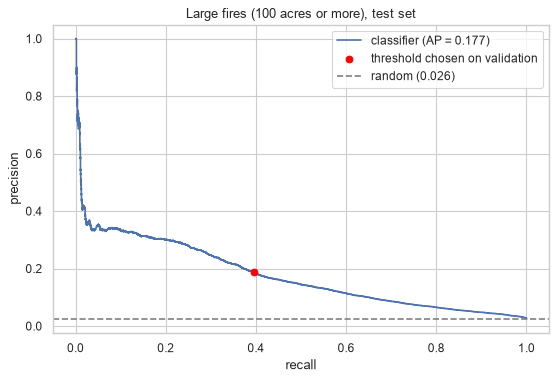

,test
share of large fires,0.0258
ROC AUC,0.8355
average precision,0.1769
share of fires flagged,0.0537
precision,0.1894
recall,0.3948


In [33]:
large_classifier = make_hgb(FEATURES_A, classifier=True, class_weight="balanced", **BEST_HGB_PARAMS)
large_classifier.fit(train_df[FEATURES_A], train_df["FIRE_SIZE"] >= 100)
threshold = np.quantile(large_classifier.predict_proba(val_df[FEATURES_A])[:, 1], 0.95)

test_scores = large_classifier.predict_proba(test_df[FEATURES_A])[:, 1]
y_large = (test_df["FIRE_SIZE"] >= 100).to_numpy()
flagged = test_scores >= threshold
precision, recall, _ = precision_recall_curve(y_large, test_scores)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall, precision, label=f"classifier (AP = {average_precision_score(y_large, test_scores):.3f})")
ax.scatter(y_large[flagged].sum() / y_large.sum(), y_large[flagged].mean(), color="red", zorder=3, label="threshold chosen on validation")
ax.axhline(y_large.mean(), color="gray", ls="--", label=f"random ({y_large.mean():.3f})")
ax.set(xlabel="recall", ylabel="precision", title="Large fires (100 acres or more), test set")
ax.legend()
plt.show()
pd.Series({"share of large fires": y_large.mean(), "ROC AUC": roc_auc_score(y_large, test_scores),
           "average precision": average_precision_score(y_large, test_scores), "share of fires flagged": flagged.mean(),
           "precision": y_large[flagged].mean(), "recall": y_large[flagged].sum() / y_large.sum()}).to_frame("test")

Observations:
- Only 2.6 % of the test fires are large, so a random guess has an average precision of 0.026. The classifier reaches 0.177, and a ROC AUC of 0.836.
- With the threshold chosen on the validation years, 5.4 % of the test fires are flagged. Among them, 18.9 % really become large (7 times more than at random), and they contain 39.5 % of all the large fires.
- This is not precise enough to replace the judgement of firefighters, but it is useful to decide which fires to look at first.

### 4.6 Comparison with a simpler setup
Our R² may look low. A more straightforward setup would make three choices that look harmless: use the duration of the fire, remove the rows with missing values (`dropna`), and split the fires at random. To see how much each choice changes the score, we start from such a setup (8 basic features and a large gradient boosting: 511 leaves, learning rate 0.1, L2 penalty 0.5, 1000 trees) and change the choices one at a time. All scores are on validation data.

In [34]:
BASIC_FEATURES = ["FIRE_YEAR", "DOY", "DURATION_DAYS", "LATITUDE", "LONGITUDE", "STATE", "CAUSE", "OWNER"]
BASIC_PARAMS = dict(max_iter=1000, max_leaf_nodes=511, l2_regularization=0.5, learning_rate=0.1, min_samples_leaf=20)


def basic_setup_r2(data, features, split):
    if split == "random":
        train, rest = train_test_split(data, test_size=0.3, random_state=RANDOM_STATE)
        val, _ = train_test_split(rest, test_size=0.5, random_state=RANDOM_STATE)
    else:
        train, val = data[data["FIRE_YEAR"] <= 2011], data[data["FIRE_YEAR"].between(2012, 2013)]
    model = make_hgb(features, **BASIC_PARAMS).fit(train[features], train[TARGET])
    return r2_score(val[TARGET], model.predict(val[features]))


with_duration_all = df.dropna(subset=["DURATION_DAYS"])
dropna_rows = df[~df["COUNTY_MISSING"] & df["DURATION_DAYS"].notna()]
no_duration = [f for f in BASIC_FEATURES if f != "DURATION_DAYS"]
setups = [
    ("1. dropna, random split, with duration", dropna_rows, BASIC_FEATURES, "random"),
    ("2. all fires with a duration, random split, with duration", with_duration_all, BASIC_FEATURES, "random"),
    ("3. all fires with a duration, split by year, with duration", with_duration_all, BASIC_FEATURES, "temporal"),
    ("4. all fires, random split, without duration", df, no_duration, "random"),
    ("5. all fires, split by year, without duration", df, no_duration, "temporal"),
]
setup_comparison = pd.DataFrame([{"setup": name, "n_fires": len(data), "val_R2": basic_setup_r2(data, features, split)}
                                 for name, data, features, split in setups]).set_index("setup")
setup_comparison.loc["6. our model (split by year, no duration, all features, tuned)"] = (len(df), learning_curve.loc[len(train_df), "R2"])
setup_comparison["n_fires"] = setup_comparison["n_fires"].astype(int)
pd.set_option("display.max_colwidth", 100)
setup_comparison

,n_fires,val_R2
setup,,
"1. dropna, random split, with duration",668179,0.5415
"2. all fires with a duration, random split, with duration",987291,0.5562
"3. all fires with a duration, split by year, with duration",987291,0.4321
"4. all fires, random split, without duration",1877708,0.3004
"5. all fires, split by year, without duration",1877708,0.1526
"6. our model (split by year, no duration, all features, tuned)",1877708,0.2227


Observations (validation R²):
- The simple setup with `dropna`, a random split and the duration reaches 0.542, more than twice our score.
- Removing the `dropna` does not lower the score (0.556), so dropping rows did not help; it only removed data and changed the population (2.5).
- Going from a random split to a split by year costs 0.12 with the duration (0.556 to 0.432) and 0.15 without it (0.300 to 0.153). The random split is optimistic because fires from the same day and place end up on both sides.
- Removing the duration costs 0.28 (0.432 to 0.153 with a split by year).
- With the same honest protocol, our features and our tuning raise the R² from 0.153 to 0.223 (+46 %).
- So a score around 0.5 mostly comes from the duration (information from after the fire) and from the random split. Our lower score answers a harder but more realistic question.

## 5. Conclusion

### What we did
We predicted the final burned area of US wildfires (log of the size) using only what is known when a fire is discovered. We checked every column for leakage and found, besides the expected columns, records that only exist because of an ICS-209 report. We cleaned the data in one function without dropping rows, built features describing when, where, why and by whom the fire was reported, and split the data by year. We compared five models, tuned the best one, drew a learning curve, tried PCA, ran an ablation study and evaluated the final model once on 2014-2015.

### Main results
| model | validation R² (2012-2013) | test R² (2014-2015) |
|---|---|---|
| mean | -0.007 | -0.006 |
| Ridge | 0.152 (0.168 with the best alpha) | 0.159 |
| gradient boosting, tuned | 0.223 | 0.253 |

- 62 % of the fires are predicted within a factor 2 of their true size (36 % with the mean).
- As an alarm, flagging about 5 % of the fires finds 40 % of the large ones.
- With the duration (scenario B) the R² goes up to 0.47, but the duration is only known after the fire.

### What we learned
- At discovery, most of the final size cannot be predicted from this data. Wind, dryness and the speed of the response are missing. An R² of about 0.25 is an honest result; scores around 0.5 need the duration or a random split (4.6).
- The location is the most useful information, mainly through the past fire activity of the place. Cause and season matter together with the location, which is why trees work better than linear models.
- Gradient boosting is the best model, as in the literature: it learns thresholds (like the -100° longitude limit) and interactions, handles missing values and scales to millions of fires.
- More data helps only up to about a million fires; after that the features are the limit.
- PCA does not help tree models, because it mixes the features that trees split on.
- The evaluation protocol matters as much as the model: the random split adds 0.12 to 0.15 of R², and leaking records or a new reporting source can change the results without any change in the fires.

### Limitations
- Large fires are underestimated by a factor of up to 1,000: the model predicts an average, and at discovery a future huge fire looks like a small one.
- Some features describe how fires are reported more than the fires themselves (reporting unit, source system). They help the score but can change, as in Kansas in 2015.
- Many sizes are rounded, and the cause may sometimes be decided after an investigation.

### What we would do with more time
- Add the weather on the day of discovery (temperature, humidity, wind, rain). We started downloading it from the Open-Meteo archive (`worker.py`), but our requests used wrong dates (every date became 1 January 1970, the Julian date problem of 2.3), so we could not use it in time. With correct dates it is the most promising addition, because the weather is known at discovery.
- Use the environmental variables of FPA FOD-Attributes (Pourmohamad et al., 2024): vegetation, dryness, population.
- Model the large fires directly: a classifier for "will it become large" followed by a regression, or losses made for extreme values as in Koh (2023).
- Validate on several blocks of years instead of one, and tune with a smaller learning rate and more trees.